# Level 2 — Bifurcations with AUTO

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/02_bifurcations-with-auto.ipynb)

Follow equilibria and periodic orbits in one parameter with AUTO: Hopf points
(where an equilibrium starts or stops oscillating), folds (where two
equilibria meet and vanish), folds of periodic orbits, period doubling, and
the Neimark–Sacker bifurcation of a map. Each diagram is checked against exact
formulas, literature values or plain simulations.

| | model | what it shows |
|---|---|---|
| [08](#wilson-cowan) | Wilson–Cowan | S-shaped branch with folds, Hopf in the inhibitory time constant |
| [09](#morris-lecar) | Morris–Lecar (Hopf regime) | f–I curve, class II onset, hysteresis |
| [10](#hodgkin-huxley) | Hodgkin–Huxley | period, Hopf points, fold of orbits, bistability |
| [11](#stiff-van-der-pol) | van der Pol, $\mu = 1000$ | stiff solvers, relaxation-oscillation period |
| [12](#driven-pendulum) | driven pendulum | rest vs rotation, hysteresis, Melnikov onset |
| [13](#delayed-logistic-map) | delayed logistic map | Neimark–Sacker at $a = 2$, invariant curve |
| [14](#rossler) | Rössler | equilibria, period doubling in $c$ |
| [15](#lorenz-84) | Lorenz 84 | folds and Hopf of the westerly flow, Hadley state |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 08–15 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT and its AUTO
through pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.5.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="wilson-cowan"></a>
## 08. Wilson–Cowan: excitatory and inhibitory populations

Mean activities $u$ (excitatory) and $v$ (inhibitory) of two coupled neural
populations with the sigmoid response $f(s) = 1/(1 + e^{-s})$:

$$
\tau_e\,\dot u = -u + f(a_{ee}u - a_{ei}v - \theta_e), \qquad
\tau_i\,\dot v = -v + f(a_{ie}u - a_{ii}v - \theta_i),
$$

with $a_{ee} = 13$, $a_{ei} = 10$, $a_{ie} = 16$, $a_{ii} = 4$,
$\theta_i = 5$, $\tau_e = 2$, and first $\theta_e = 2$, $\tau_i = 6$ (in the
code $\theta_e$, $\theta_i$, $\tau_e$, $\tau_i$ are `te`, `ti`, `taue`,
`taui`).

Along the excitatory threshold $\theta_e$ the equilibria form an S-shaped
branch with two folds; and when inhibition is slow enough (large $\tau_i$) the
rest state loses stability and the network oscillates. We draw the phase plane,
follow the equilibria in $\theta_e$ and then in $\tau_i$ with AUTO, and compare
the orbits born at the Hopf point with plain simulations.

In [3]:
section("08_wilson-cowan")

### The model

`function` defines the sigmoid once for both equations. The Newton tolerance
and Jacobian step are tightened (*Sing pt ctrl*) for accurate equilibria and
eigenvalues.

In [4]:
P = dict(aee=13, aei=10, te=2, taue=2, aie=16, aii=4, ti=5, taui=6)
mb = (ModelBuilder("wilson_cowan")
      .comment("Wilson-Cowan model")
      .function("f(u)", "1/(1+exp(-u))")
      .ode("u", "(-u+f(aee*u-aei*v-te))/taue")
      .ode("v", "(-v+f(aie*u-aii*v-ti))/taui")
      .parameter(**P)
      .initial(u=0.1, v=0.1)
      .option(total=200, dt=0.05))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("te", "taui", "ti", "aee", "aei", "aie", "aii", "taue")
m.buttons.numerics.sing_pt_ctrl(500, 1e-10, 1e-8)

# Wilson-Cowan model
f(u)=1/(1+exp(-u))
u'=(-u+f(aee*u-aei*v-te))/taue
v'=(-v+f(aie*u-aii*v-ti))/taui
par aee=13,aei=10,te=2,taue=2,aie=16,aii=4,ti=5,taui=6
init u=0.1,v=0.1
@ total=200,dt=0.05
done



'prompt  Maximum iterates : [100] -> 500\nprompt  Newton tolerance : [0.001] -> 1e-10\nprompt  Jacobian epsilon : [0.001] -> 1e-08\n'

### Phase plane at $\theta_e = 2$, $\tau_i = 6$

The nullclines cross once, at an unstable equilibrium; a trajectory from
$(0.1, 0.1)$ winds out onto the limit cycle around it.

equilibrium at te = 2: <Equilibrium unstable U=0.338295, V=0.306873>  eigenvalues [0.3233+0.4855j 0.3233-0.4855j]


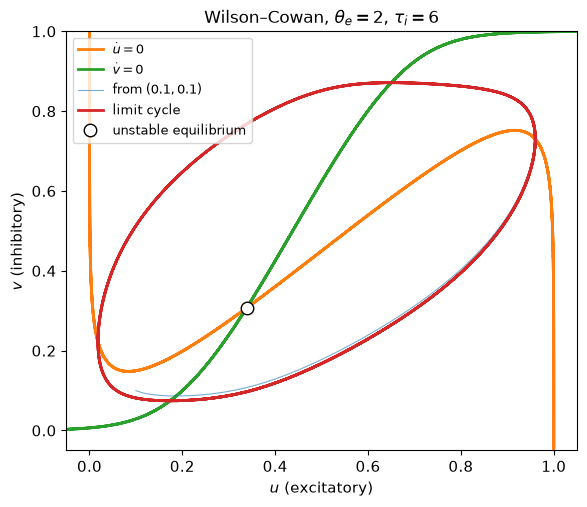

In [5]:
win = (-0.05, 1.05, -0.05, 1.0)
nc = m.nullclines(x="u", y="v", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=300)
tr = m.run(keep=False, u=0.1, v=0.1, total=300)
cyc = m.run(keep=False, u=0.1, v=0.1, total=400, trans=300)
eq = m.equilibrium({"u": 0.34, "v": 0.31})
print("equilibrium at te = 2:", eq, " eigenvalues", np.round(eq.eigenvalues, 4))

fig, ax = plt.subplots(figsize=(6, 5.2))
ax.plot(nc["U"][:, 0], nc["U"][:, 1], color="tab:orange", lw=2, label=r"$\dot u = 0$")
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:green", lw=2, label=r"$\dot v = 0$")
ax.plot(tr["u"], tr["v"], color="tab:blue", lw=0.8, alpha=0.6, label="from $(0.1, 0.1)$")
ax.plot(cyc["u"], cyc["v"], color="tab:red", lw=2, label="limit cycle")
ax.plot(eq.x["U"], eq.x["V"], "o", mfc="white", mec="k", ms=9, label="unstable equilibrium")
ax.set(xlim=win[:2], ylim=win[2:], xlabel="$u$ (excitatory)", ylabel="$v$ (inhibitory)",
       title=r"Wilson–Cowan, $\theta_e = 2$, $\tau_i = 6$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### AUTO: equilibria in $\theta_e$ (with $\tau_i = 6$)

Start on the high-activity state at $\theta_e = -3$ and follow it with small
steps (the folds are sharp). The branch is S-shaped: two folds (LP) and a Hopf
point (HB).

AUTO in te: folds at [-0.99263 -0.4457 ]  Hopf at [3.17105]


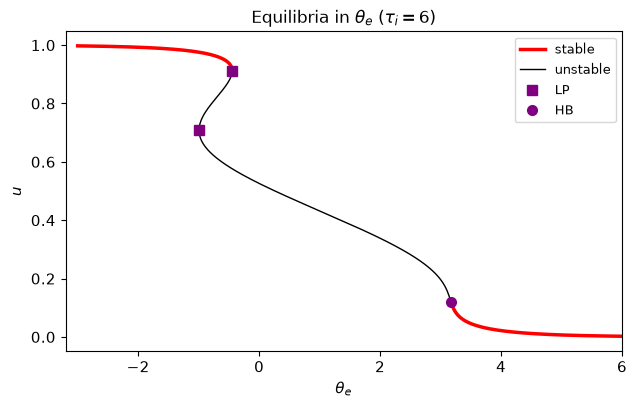

In [6]:
m.set(te=-3)
m.run(total=300)
m.run_last(total=10)
eqt = m.auto.run("te", start="steady", ds=0.002, dsmax=0.01, parmin=-4, parmax=6, nmax=4000)
lp_te = sorted(p.x for p in eqt.special("LP"))
hb_te = [p.x for p in eqt.special("HB")]
print("AUTO in te: folds at", np.round(lp_te, 5), " Hopf at", np.round(hb_te, 5))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs = np.array([p.x for p in eqt])
us = np.array([p.u0["u"] for p in eqt])
st = np.array([bool(p.stable) for p in eqt])
ax.plot(xs, np.where(st, us, np.nan), "r-", lw=2.5, label="stable")
ax.plot(xs, np.where(~st, us, np.nan), "k-", lw=1, label="unstable")
for kind, mk in (("LP", "s"), ("HB", "o")):
    pts = eqt.special(kind)
    ax.plot([p.x for p in pts], [p.u0["u"] for p in pts], mk, color="purple", ms=7, label=kind)
ax.set(xlim=(-3.2, 6), xlabel=r"$\theta_e$", ylabel="$u$", title=r"Equilibria in $\theta_e$ ($\tau_i = 6$)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "equilibria_te.png")

### Slow inhibition: equilibria and orbits in $\tau_i$ at $\theta_e = 2$

A new diagram (`m.auto.reset()`): follow the equilibrium at $\theta_e = 2$ from
$\tau_i = 1$ upwards. At the Hopf point slow inhibition starts the oscillation;
$\ell_1 < 0$ means it is supercritical (a small stable orbit is born). The
periodic orbits are then followed from the Hopf point, and the same amplitude
and period are measured from plain simulations (period from upward crossings
of $u = 0.5$).

AUTO in taui: Hopf at taui = 1.93796, l1 = -4.220, period at onset 6.1218


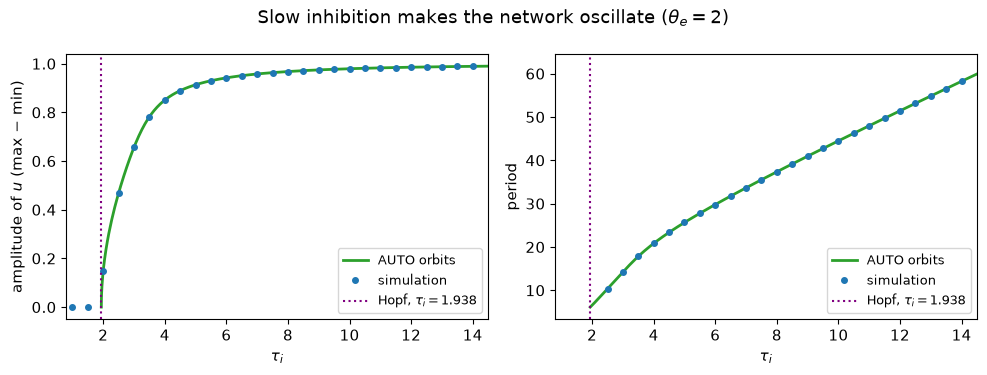

In [7]:
m.auto.reset()
m.set(te=2, taui=1)
m.run(total=300)
m.run_last(total=10)
eqi = m.auto.run("taui", start="steady", ds=0.002, dsmax=0.01, parmin=0.5, parmax=15, nmax=4000)
hb = eqi.special("HB")[0]
l1, om = m.auto.lyapunov(hb)
print(f"AUTO in taui: Hopf at taui = {hb.x:.5f}, l1 = {l1:.3f}, period at onset {2 * np.pi / om:.4f}")
po = m.auto.run(grab=hb.label, choice="periodic", ntst=60, ds=0.002, dsmax=0.05, nmax=500, parmax=15)

T = np.linspace(1.0, 14.0, 27)
amp, per = [], []
for ti_ in T:
    s = m.run(keep=False, te=2, taui=ti_, u=0.1, v=0.1, total=1500, trans=1000)
    up = np.where((s["u"][:-1] < 0.5) & (s["u"][1:] >= 0.5))[0]
    amp.append(np.ptp(s["u"]))
    per.append(np.diff(s.t[up]).mean() if len(up) > 2 else np.nan)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
px = np.array([p.x for p in po])
axs[0].plot(px, [p.umax["u"] - p.umin["u"] for p in po], "-", color="tab:green", lw=2, label="AUTO orbits")
axs[0].plot(T, amp, "o", color="tab:blue", ms=4, label="simulation")
axs[1].plot(px, [p.period for p in po], "-", color="tab:green", lw=2, label="AUTO orbits")
axs[1].plot(T, per, "o", color="tab:blue", ms=4, label="simulation")
for ax, lab in zip(axs, ("amplitude of $u$ (max $-$ min)", "period")):
    ax.axvline(hb.x, color="purple", ls=":", label=rf"Hopf, $\tau_i = {hb.x:.3f}$")
    ax.set(xlabel=r"$\tau_i$", ylabel=lab, xlim=(0.8, 14.5))
    ax.legend()
fig.suptitle(r"Slow inhibition makes the network oscillate ($\theta_e = 2$)")
fig.tight_layout()
fig.savefig(FIG / "oscillations_taui.png")

### Checks

On an equilibrium the second equation gives $a_{ie}u - a_{ii}v - \theta_i =
\operatorname{logit} v$ with $\operatorname{logit} x = \ln\frac{x}{1-x}$, so
$u$ is explicit in $v$, and then the first equation gives $\theta_e$: the
whole branch is a curve parametrised by $v$,

$$
u(v) = \frac{\operatorname{logit} v + a_{ii}v + \theta_i}{a_{ie}}, \qquad
\theta_e(v) = a_{ee}\,u(v) - a_{ei}\,v - \operatorname{logit} u(v).
$$

* The folds are where $d\theta_e/dv = 0$.
* On the branch $f' = u(1-u)$ and $v(1-v)$, so the trace of the Jacobian is

$$
\operatorname{tr} J = \frac{-1 + a_{ee}\,u(1-u)}{\tau_e} - \frac{1 + a_{ii}\,v(1-v)}{\tau_i},
$$

  and the Hopf point in $\theta_e$ (at $\tau_i = 6$) is where it vanishes.
* At $\theta_e = 2$ the equilibrium does not depend on $\tau_i$; the trace
  vanishes at

$$
\tau_i^{\mathrm{H}} = \tau_e\,\frac{1 + a_{ii}\,v(1-v)}{a_{ee}\,u(1-u) - 1},
$$

  and the period at onset is $2\pi/\sqrt{\det J}$ with
  $\det J = \bigl[-(a_{ee}f_u - 1)(1 + a_{ii}f_v) + a_{ei}a_{ie}f_uf_v\bigr]/(\tau_e\tau_i)$,
  $f_u = u(1-u)$, $f_v = v(1-v)$.
* The Hopf point is supercritical, and simulation and collocation (two
  independent methods) give the same period at $\tau_i = 6$.

In [8]:
def root(fun, a, b, n=200):
    for _ in range(n):
        c = 0.5 * (a + b)
        a, b = (c, b) if np.sign(fun(c)) == np.sign(fun(a)) else (a, c)
    return 0.5 * (a + b)


def roots(fun, lo, hi):
    x = np.linspace(lo, hi, 20001)
    y = fun(x)
    return [root(fun, x[k], x[k + 1]) for k in np.where(np.sign(y[:-1]) != np.sign(y[1:]))[0]]


logit = lambda x: np.log(x / (1 - x))
u_of = lambda v: (logit(v) + P["aii"] * v + P["ti"]) / P["aie"]
te_of = lambda v: P["aee"] * u_of(v) - P["aei"] * v - logit(u_of(v))
dte = lambda v: ((P["aee"] - 1 / (u_of(v) * (1 - u_of(v)))) * (1 / (v * (1 - v)) + P["aii"]) / P["aie"]
                 - P["aei"])
vgrid = (root(u_of, 1e-12, 0.5) + 1e-9, root(lambda v: u_of(v) - 1, 0.5, 1 - 1e-12) - 1e-9)
te_folds = sorted(te_of(np.array(roots(dte, *vgrid))))
check("fold 1 in te (exact)", lp_te[0], te_folds[0], 1e-4)
check("fold 2 in te (exact)", lp_te[1], te_folds[1], 1e-4)


def trace(v, taui):
    u = u_of(v)
    return (-1 + P["aee"] * u * (1 - u)) / P["taue"] - (1 + P["aii"] * v * (1 - v)) / taui


vh = roots(lambda v: trace(v, 6), *vgrid)
check("Hopf in te at taui = 6 (exact, trace = 0)", hb_te[0], te_of(vh[0]), 1e-4)
v2 = roots(lambda v: te_of(v) - 2, *vgrid)[0]
u2 = u_of(v2)
fu, fv = u2 * (1 - u2), v2 * (1 - v2)
taui_h = P["taue"] * (1 + P["aii"] * fv) / (P["aee"] * fu - 1)
check("equilibrium u at te = 2 (exact)", eq.x["U"], u2, 1e-6)
check("Hopf in taui (exact)", hb.x, taui_h, 1e-4)
det = (-(-1 + P["aee"] * fu) * (1 + P["aii"] * fv) + P["aei"] * fu * P["aie"] * fv) / (P["taue"] * taui_h)
check("period at onset 2*pi/sqrt(det) (exact)", 2 * np.pi / om, 2 * np.pi / np.sqrt(det), 1e-3)
check("Hopf is supercritical (1 = l1 < 0)", float(l1 < 0), 1, 0)
k = np.argmin(abs(T - 6))
check("period at taui = 6: simulation vs AUTO", per[k], np.interp(6, px, [p.period for p in po]), 0.05)
checks_done()

  ok   fold 1 in te (exact): -0.992634 (expected -0.992634)
  ok   fold 2 in te (exact): -0.445699 (expected -0.445698)
  ok   Hopf in te at taui = 6 (exact, trace = 0): 3.17105 (expected 3.17104)
  ok   equilibrium u at te = 2 (exact): 0.338295 (expected 0.338295)
  ok   Hopf in taui (exact): 1.93796 (expected 1.93795)
  ok   period at onset 2*pi/sqrt(det) (exact): 6.12176 (expected 6.12175)
  ok   Hopf is supercritical (1 = l1 < 0): 1 (expected 1)
  ok   period at taui = 6: simulation vs AUTO: 29.8 (expected 29.7973)

08_wilson-cowan: 8/8 checks passed


<a id="morris-lecar"></a>
## 09. Morris–Lecar: a neuron with a Hopf onset (class II)

The Morris–Lecar model of a barnacle muscle fibre in Rinzel and Ermentrout's
parameters: a calcium current with instant activation $m_\infty(v)$ and a
potassium current with recovery variable $w$ ($t$ in ms, $v$ in mV):

$$
C\,\dot v = i + g_L(v_L - v) + g_K\,w\,(v_K - v) + g_{Ca}\,m_\infty(v)\,(v_{Ca} - v), \qquad
\dot w = \phi\,\frac{w_\infty(v) - w}{\tau_w(v)},
$$

$$
m_\infty(v) = \tfrac12\Bigl(1 + \tanh\frac{v - v_1}{v_2}\Bigr), \quad
w_\infty(v) = \tfrac12\Bigl(1 + \tanh\frac{v - v_3}{v_4}\Bigr), \quad
\tau_w(v) = \frac{1}{\cosh\bigl((v - v_3)/(2v_4)\bigr)},
$$

with $C = 20$, $g_L = 2$, $g_K = 8$, $g_{Ca} = 4.4$, $v_L = -60$,
$v_K = -84$, $v_{Ca} = 120$, $v_1 = -1.2$, $v_2 = 18$, $v_3 = 2$,
$v_4 = 30$, $\phi = 0.04$.

Repetitive firing starts at a Hopf bifurcation as the applied current $i$
grows, and it starts at a nonzero frequency: a *class II* neuron in Hodgkin's
sense. We measure the f–I curve by sweeping $i$ up and down, and explain it,
including its hysteresis, with AUTO's equilibria and periodic orbits.

In [9]:
section("09_morris-lecar")

### The model

`aux` adds the calcium current as an extra output column. `rate` counts spikes
per second from upward crossings of $v = 0$ (time is in ms).

In [10]:
P = dict(i=60, c=20, vk=-84, vl=-60, vca=120, gk=8, gl=2, gca=4.4, v1=-1.2, v2=18, v3=2, v4=30, phi=0.04)
mb = (ModelBuilder("morris_lecar")
      .comment("Morris-Lecar neuron, Hopf regime (Rinzel & Ermentrout)")
      .function("minf(v)", ".5*(1+tanh((v-v1)/v2))")
      .function("winf(v)", ".5*(1+tanh((v-v3)/v4))")
      .function("tauw(v)", "1/cosh((v-v3)/(2*v4))")
      .ode("v", "(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c")
      .ode("w", "phi*(winf(v)-w)/tauw(v)")
      .aux("ica", "gca*minf(v)*(v-vca)")
      .parameter(**P)
      .initial(v=-60, w=0.015)
      .option(total=400, dt=0.25, meth="rk4", bound=10000))
print(mb.render())
m = mb.load(ODE)


def rate(tr):
    v = tr["v"]
    up = tr.t[1:][(v[:-1] < 0) & (v[1:] >= 0)]
    return 1000 / np.diff(up).mean() if len(up) > 2 else 0.0

# Morris-Lecar neuron, Hopf regime (Rinzel & Ermentrout)
minf(v)=.5*(1+tanh((v-v1)/v2))
winf(v)=.5*(1+tanh((v-v3)/v4))
tauw(v)=1/cosh((v-v3)/(2*v4))
v'=(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c
w'=phi*(winf(v)-w)/tauw(v)
aux ica=gca*minf(v)*(v-vca)
par i=60,c=20,vk=-84,vl=-60,vca=120,gk=8,gl=2,gca=4.4,v1=-1.2,v2=18,v3=2,v4=30,phi=0.04
init v=-60,w=0.015
@ total=400,dt=0.25,meth=rungekutta,bound=10000
done



### Voltage traces

Rest at $i = 60$, repetitive firing at $i = 100$, and a depolarised rest at
$i = 230$.

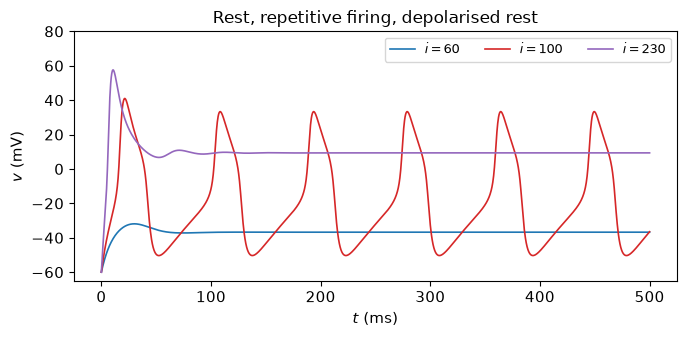

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i_, col in ((60, "tab:blue"), (100, "tab:red"), (230, "tab:purple")):
    tr = m.run(keep=False, i=i_, total=500)
    ax.plot(tr.t, tr["v"], color=col, lw=1.2, label=f"$i = {i_}$")
ax.set(xlabel="$t$ (ms)", ylabel="$v$ (mV)", ylim=(-65, 80), title="Rest, repetitive firing, depolarised rest")
ax.legend(loc="upper right", ncol=3)
fig.tight_layout()
fig.savefig(FIG / "traces.png")

### f–I curve from simulations

Sweep $i$ up from rest and then down from firing; each run starts where the
last one ended, so the cell keeps its state (resting or firing) as long as that
state exists. The two sweeps differ: hysteresis.

In [12]:
I = np.arange(80.0, 240.1, 1.0)
state = {"v": -60, "w": 0.015}
f_up, f_down = [], []
for i_ in I:
    tr = m.run(keep=False, i=i_, total=2000, trans=1000, **state)
    f_up.append(rate(tr))
    state = {"v": tr["v"][-1], "w": tr["w"][-1]}
for i_ in I[::-1]:
    tr = m.run(keep=False, i=i_, total=2000, trans=1000, **state)
    f_down.append(rate(tr))
    state = {"v": tr["v"][-1], "w": tr["w"][-1]}
f_up, f_down = np.array(f_up), np.array(f_down[::-1])
on_up = I[np.argmax(f_up > 0)]
on_down = I[np.argmax(f_down > 0)]
print(f"sweeping up: firing from i = {on_up:g} at {f_up[f_up > 0][0]:.2f} Hz;"
      f" sweeping down: firing down to i = {on_down:g} at {f_down[f_down > 0][0]:.2f} Hz")

sweeping up: firing from i = 95 at 10.97 Hz; sweeping down: firing down to i = 89 at 9.23 Hz


### AUTO: equilibria in $i$, Hopf points, orbits between them

AUTO's tolerances are tightened from $10^{-4}$ to $10^{-6}$ to get the Hopf
points to about $10^{-5}$. Both Hopf points are subcritical ($\ell_1 > 0$).
The periodic orbits are followed from HB1 for one pass to HB2 (the branch is
cut at the end point, labelled BP). Their folds (LP) bound the range where a
stable orbit exists; the rate $1000/T$ of the orbits is drawn on the simulated
f–I curve.

Hopf at i = 93.8576: l1 = +0.00654 (subcritical), frequency at onset 12.697 Hz


Hopf at i = 212.0188: l1 = +0.00367 (subcritical), frequency at onset 23.651 Hz


folds of periodic orbits at i = [88.2933, 216.8998]
orbit at the lower fold: period 135.33 ms, 7.39 Hz


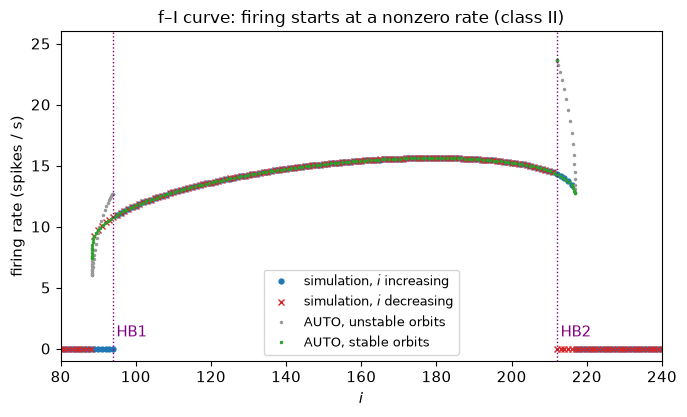

In [13]:
m.set(i=0)
m.run(total=1000)
m.run_last(total=10)
eqs = m.auto.run("i", start="steady", ds=0.5, dsmax=2, parmin=0, parmax=300, nmax=2000,
                 epsl=1e-6, epsu=1e-6, epss=1e-6)
hbs = eqs.special("HB")
for p in hbs:
    l1, om = m.auto.lyapunov(p)
    print(f"Hopf at i = {p.x:.4f}: l1 = {l1:+.5f} ({'sub' if l1 > 0 else 'super'}critical), "
          f"frequency at onset {1000 * om / (2 * np.pi):.3f} Hz")
po = list(m.auto.run(grab=hbs[0].label, choice="periodic", ntst=100, ds=0.2, dsmax=1, nmax=300))
po = po[:next(k for k, p in enumerate(po) if p.type == "BP") + 1]
lps = sorted({round(p.x, 4) for p in po if p.type == "LP"})
print("folds of periodic orbits at i =", lps)
pst = [p for p in po if p.stable]
lp1 = min((p for p in po if p.type == "LP"), key=lambda p: p.x)
print(f"orbit at the lower fold: period {lp1.period:.2f} ms, {1000 / lp1.period:.2f} Hz")

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(I, f_up, "o", color="tab:blue", ms=3.5, label="simulation, $i$ increasing")
ax.plot(I, f_down, "x", color="tab:red", ms=4, label="simulation, $i$ decreasing")
pun = [p for p in po if not p.stable]
ax.plot([p.x for p in pun], [1000 / p.period for p in pun], ".", color="0.6", ms=3, label="AUTO, unstable orbits")
ax.plot([p.x for p in pst], [1000 / p.period for p in pst], ".", color="tab:green", ms=3, label="AUTO, stable orbits")
for p in hbs:
    ax.axvline(p.x, color="purple", ls=":", lw=1)
ax.text(hbs[0].x + 1, 1, "HB1", color="purple")
ax.text(hbs[1].x + 1, 1, "HB2", color="purple")
ax.set(xlabel="$i$", ylabel="firing rate (spikes / s)", xlim=(80, 240), ylim=(-1, 26),
       title="f–I curve: firing starts at a nonzero rate (class II)")
ax.legend(loc="lower center")
fig.tight_layout()
fig.savefig(FIG / "f_I_curve.png")

### Checks

On an equilibrium $w = w_\infty(v)$, so $i$ is explicit in $v$:

$$
i(v) = -\bigl[g_L(v_L - v) + g_K\,w_\infty(v)(v_K - v) + g_{Ca}\,m_\infty(v)(v_{Ca} - v)\bigr].
$$

With the Jacobian entries $a_{11}, a_{12}, a_{21}, a_{22}$ written out on the
branch, a Hopf point is where $\operatorname{tr} J = a_{11} + a_{22} = 0$, and
the frequency there is $\omega/2\pi$ with
$\omega = \sqrt{a_{11}a_{22} - a_{12}a_{21}}$ (in Hz: times 1000).

* Both Hopf points and their frequencies (exact), and HB1 subcritical.
* The simulations jump to firing at HB1 going up (none fires below it), and
  keep firing on the way down until the fold of orbits (on the grid of step 1).
  Just above HB1 the focus is only weakly unstable (at $i = 94$ the
  eigenvalues have real part $5\times10^{-4}$ per ms), so leaving rest takes
  many seconds and the up-sweep fires from the next grid points.
* Class II: the lowest rate is that of the stable orbit at the fold, far from
  zero; the simulated rates agree with AUTO's stable orbits.

In [14]:
th = lambda v, a, b: np.tanh((v - a) / b)
minf = lambda v: 0.5 * (1 + th(v, P["v1"], P["v2"]))
winf = lambda v: 0.5 * (1 + th(v, P["v3"], P["v4"]))
tauw = lambda v: 1 / np.cosh((v - P["v3"]) / (2 * P["v4"]))
i_of = lambda v: -(P["gl"] * (P["vl"] - v) + P["gk"] * winf(v) * (P["vk"] - v)
                   + P["gca"] * minf(v) * (P["vca"] - v))
a11 = lambda v: (-P["gl"] - P["gk"] * winf(v) - P["gca"] * minf(v)
                 + P["gca"] * (1 - th(v, P["v1"], P["v2"])**2) / (2 * P["v2"]) * (P["vca"] - v)) / P["c"]
a22 = lambda v: -P["phi"] / tauw(v)
a12 = lambda v: P["gk"] * (P["vk"] - v) / P["c"]
a21 = lambda v: P["phi"] * (1 - th(v, P["v3"], P["v4"])**2) / (2 * P["v4"]) / tauw(v)
tr_ = lambda v: a11(v) + a22(v)
vg = np.linspace(-60, 40, 100001)
vh = []
for k in np.where(np.sign(tr_(vg[:-1])) != np.sign(tr_(vg[1:])))[0]:
    a, b = vg[k], vg[k + 1]
    for _ in range(60):
        c = 0.5 * (a + b)
        a, b = (c, b) if np.sign(tr_(c)) == np.sign(tr_(a)) else (a, c)
    vh.append(0.5 * (a + b))
for p, v in zip(hbs, vh):
    k = 1 if p is hbs[0] else 2
    check(f"HB{k} at i (exact, trace = 0)", p.x, i_of(v), 1e-3)
    om_exact = np.sqrt(a11(v) * a22(v) - a12(v) * a21(v))
    check(f"HB{k} frequency in Hz (exact)", 1000 * m.auto.lyapunov(p)[1] / (2 * np.pi),
          1000 * om_exact / (2 * np.pi), 1e-3)
check("HB1 is subcritical (1 = l1 > 0)", float(m.auto.lyapunov(hbs[0])[0] > 0), 1, 0)
check("no firing below HB1 sweeping up (count)", np.sum((f_up > 0) & (I < hbs[0].x)), 0, 0)
check("last firing sweeping down = fold of orbits (grid)", on_down, np.ceil(lp1.x), 0)
sx, sf = np.array([[p.x, 1000 / p.period] for p in sorted(pst, key=lambda p: p.x) if p.x < 200]).T
check("lowest simulated rate vs AUTO stable orbit there (Hz)", f_down[f_down > 0][0],
      np.interp(on_down, sx, sf), 0.02)
check("rate at i = 150: simulation vs AUTO (Hz)", f_up[I == 150][0], np.interp(150, sx, sf), 0.02)
checks_done()

  ok   HB1 at i (exact, trace = 0): 93.8576 (expected 93.8576)


  ok   HB1 frequency in Hz (exact): 12.6973 (expected 12.6973)
  ok   HB2 at i (exact, trace = 0): 212.019 (expected 212.019)


  ok   HB2 frequency in Hz (exact): 23.6508 (expected 23.6508)


  ok   HB1 is subcritical (1 = l1 > 0): 1 (expected 1)
  ok   no firing below HB1 sweeping up (count): 0 (expected 0)
  ok   last firing sweeping down = fold of orbits (grid): 89 (expected 89)
  ok   lowest simulated rate vs AUTO stable orbit there (Hz): 9.23254 (expected 9.22871)
  ok   rate at i = 150: simulation vs AUTO (Hz): 15.1147 (expected 15.1144)

09_morris-lecar: 9/9 checks passed


<a id="hodgkin-huxley"></a>
## 10. Hodgkin–Huxley: the squid giant axon

The four-variable Hodgkin–Huxley model ($v$ in mV, $t$ in ms, $i$ in
$\mu$A/cm$^2$): sodium activation $m$ and inactivation $h$, potassium
activation $n$,

$$
C_m\,\dot v = i - g_{Na}\,m^3h\,(v - E_{Na}) - g_K\,n^4\,(v - E_K) - g_L\,(v - E_L),
$$

$$
\dot x = \alpha_x(v)\,(1 - x) - \beta_x(v)\,x, \qquad x = m, h, n,
$$

with $g_{Na} = 120$, $g_K = 36$, $g_L = 0.3$, $E_{Na} = 50$, $E_K = -77$,
$E_L = -54.4$, $C_m = 1$ and the rate functions

$$
\alpha_m = \frac{0.1\,(v + 40)}{1 - e^{-(v+40)/10}}, \quad \beta_m = 4\,e^{-(v+65)/18}, \quad
\alpha_h = 0.07\,e^{-(v+65)/20}, \quad \beta_h = \frac{1}{1 + e^{-(v+35)/10}},
$$

$$
\alpha_n = \frac{0.01\,(v + 55)}{1 - e^{-(v+55)/10}}, \quad \beta_n = 0.125\,e^{-(v+65)/80}.
$$

At $i = 10$ it fires repeatedly. Repetitive firing begins at a fold of
periodic orbits near $i = 6.26$, below the subcritical Hopf point at
$i = 9.78$, so between the two the cell can rest or fire depending on how it
starts. The $(v, n)$ plane is only a projection of the 4-D phase space: there
are no nullclines to draw.

In [15]:
section("10_hodgkin-huxley")

### The model

The removable singularities of $\alpha_m$ and $\alpha_n$ (0/0 at $v = -40$ and
$v = -55$) are replaced by their limits with `if(...)then(...)else(...)`.

In [16]:
P = dict(i=10, gna=120, gk=36, gl=0.3, ena=50, ek=-77, el=-54.4, cm=1)
mb = (ModelBuilder("hodgkin_huxley")
      .comment("Hodgkin-Huxley model of the squid giant axon: v in mV, t in ms, i in uA/cm^2")
      .function("am(v)", "if(abs(v+40)<1e-7)then(1)else(0.1*(v+40)/(1-exp(-(v+40)/10)))")
      .function("bm(v)", "4*exp(-(v+65)/18)")
      .function("ah(v)", "0.07*exp(-(v+65)/20)")
      .function("bh(v)", "1/(1+exp(-(v+35)/10))")
      .function("an(v)", "if(abs(v+55)<1e-7)then(0.1)else(0.01*(v+55)/(1-exp(-(v+55)/10)))")
      .function("bn(v)", "0.125*exp(-(v+65)/80)")
      .ode("v", "(i-gna*m^3*h*(v-ena)-gk*n^4*(v-ek)-gl*(v-el))/cm")
      .ode("m", "am(v)*(1-m)-bm(v)*m")
      .ode("h", "ah(v)*(1-h)-bh(v)*h")
      .ode("n", "an(v)*(1-n)-bn(v)*n")
      .parameter(**P)
      .initial(v=-65, m=0.05, h=0.6, n=0.32)
      .option(total=300, dt=0.02, meth="rk4"))
print(mb.render())
m = mb.load(ODE)

# Hodgkin-Huxley model of the squid giant axon: v in mV, t in ms, i in uA/cm^2
am(v)=if(abs(v+40)<1e-7)then(1)else(0.1*(v+40)/(1-exp(-(v+40)/10)))
bm(v)=4*exp(-(v+65)/18)
ah(v)=0.07*exp(-(v+65)/20)
bh(v)=1/(1+exp(-(v+35)/10))
an(v)=if(abs(v+55)<1e-7)then(0.1)else(0.01*(v+55)/(1-exp(-(v+55)/10)))
bn(v)=0.125*exp(-(v+65)/80)
v'=(i-gna*m^3*h*(v-ena)-gk*n^4*(v-ek)-gl*(v-el))/cm
m'=am(v)*(1-m)-bm(v)*m
h'=ah(v)*(1-h)-bh(v)*h
n'=an(v)*(1-n)-bn(v)*n
par i=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4,cm=1
init v=-65,m=0.05,h=0.6,n=0.32
@ total=300,dt=0.02,meth=rungekutta
done



### The period at $i = 10$

XPP's *Initialconds → Periodic* finds one period of the stable orbit (it sets
the total integration time to the period).

In [17]:
m.run(total=300, trans=0)
m.buttons.initialconds.periodic()
T10 = m.numerics["total"]
print(m.transcript.strip().splitlines()[-1])
m.set(total=300)

message Period T=14.638325. Starting at max of V; total set to T


<pyxpp.Model 10_hodgkin-huxley.ode: vars=['V', 'M', 'H', 'N'] aux=[] pars=8>

### AUTO: rest state in $i$, Hopf points, periodic orbits

Start at rest at $i = 0$, below both Hopf points (near 9.78 and 154.5). The
periodic orbits from HB1 are kept up to the second Hopf point; their folds
mark where stable firing begins. The right panel zooms on the bistable range
between the lowest fold and HB1.

Hopf points at i = 9.7792 (l1 = +0.0148) and 154.5267


folds of periodic orbits at i = [6.2642 7.8462 7.9217]


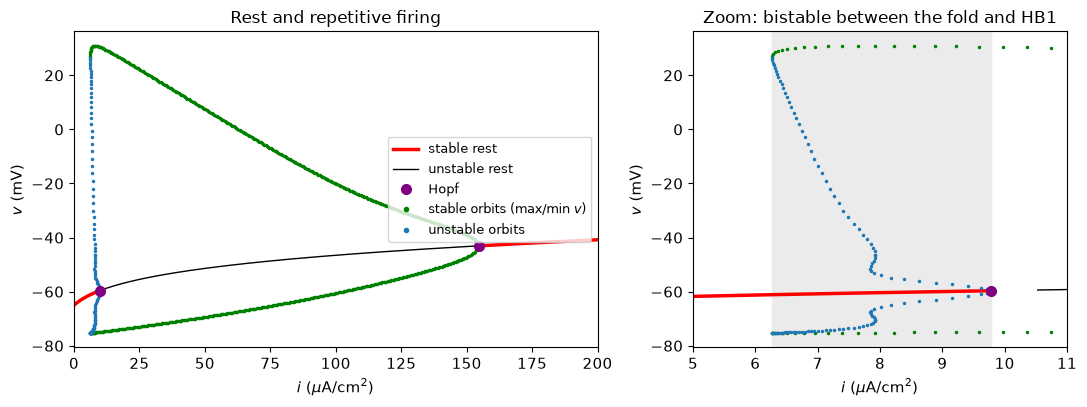

In [18]:
m.set(i=0)
m.run(total=300)
m.run_last(total=10)
eqs = m.auto.run("i", start="steady", ds=0.2, dsmax=0.8, parmin=0, parmax=200, nmax=2000)
hb1, hb2 = sorted(eqs.special("HB"), key=lambda p: p.x)
l1, om = m.auto.lyapunov(hb1)
print(f"Hopf points at i = {hb1.x:.4f} (l1 = {l1:+.4f}) and {hb2.x:.4f}")
po = list(m.auto.run(grab=hb1.label, choice="periodic", ntst=60, ds=0.05, dsmax=0.5, nmax=400))
po = po[:next(k for k, p in enumerate(po) if p.type == "BP") + 1]
lps = sorted(p.x for p in po if p.type == "LP")
print("folds of periodic orbits at i =", np.round(lps, 4))
stab = sorted([(p.x, p.period) for p in po if p.stable and p.x < 140])
sx, sT = np.array(stab).T

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
xs = np.array([p.x for p in eqs])
vs = np.array([p.u0["v"] for p in eqs])
st = np.array([bool(p.stable) for p in eqs])
px = np.array([p.x for p in po])
pst = np.array([bool(p.stable) for p in po])
for ax in axs:
    ax.plot(xs, np.where(st, vs, np.nan), "r-", lw=2.5, label="stable rest")
    ax.plot(xs, np.where(~st, vs, np.nan), "k-", lw=1, label="unstable rest")
    for f in ("umax", "umin"):
        ys = np.array([getattr(p, f)["v"] for p in po])
        ax.plot(px[pst], ys[pst], "g.", ms=3)
        ax.plot(px[~pst], ys[~pst], ".", color="tab:blue", ms=3)
    ax.plot([hb1.x, hb2.x], [hb1.u0["v"], hb2.u0["v"]], "o", color="purple", ms=7, label="Hopf")
    ax.set(xlabel=r"$i$ ($\mu$A/cm$^2$)", ylabel="$v$ (mV)")
axs[0].plot([], [], "g.", label="stable orbits (max/min $v$)")
axs[0].plot([], [], ".", color="tab:blue", label="unstable orbits")
axs[0].set(xlim=(0, 200), title="Rest and repetitive firing")
axs[0].legend(loc="center right")
axs[1].axvspan(lps[0], hb1.x, color="0.92", zorder=0)
axs[1].set(xlim=(5, 11), title="Zoom: bistable between the fold and HB1")
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Bistability at $i = 8$

From the stable rest state, a 2 mV kick dies out, while a 10 mV kick starts
repetitive firing on the stable orbit (period from crossings of $v = 0$ after
$t = 150$).

i = 8: rest at v = -60.355 mV (stable: True); kicked cell fires, period 16.013 ms


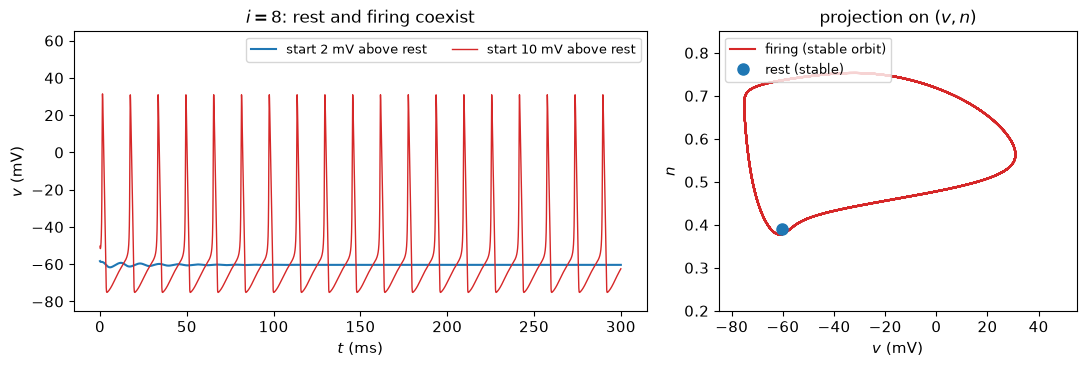

In [19]:
m.set(i=8)
rest = m.equilibrium({"v": -62, "m": 0.07, "h": 0.5, "n": 0.36})
r0 = {k.lower(): v for k, v in rest.x.items()}
quiet = m.run(keep=False, total=300, **{**r0, "v": r0["v"] + 2})
kick = m.run(keep=False, total=300, **{**r0, "v": r0["v"] + 10})
late = kick.t > 150
up = kick.t[1:][(kick["v"][:-1] < 0) & (kick["v"][1:] >= 0)]
T8 = np.diff(up[up > 150]).mean()
print(f"i = 8: rest at v = {rest.x['V']:.3f} mV (stable: {rest.stable}); kicked cell fires, period {T8:.3f} ms")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
axs[0].plot(quiet.t, quiet["v"], color="tab:blue", lw=1.5, label="start 2 mV above rest")
axs[0].plot(kick.t, kick["v"], color="tab:red", lw=1, label="start 10 mV above rest")
axs[0].set(xlabel="$t$ (ms)", ylabel="$v$ (mV)", ylim=(-85, 65), title="$i = 8$: rest and firing coexist")
axs[0].legend(loc="upper right", ncol=2)
axs[1].plot(kick["v"][late], kick["n"][late], color="tab:red", lw=1.5, label="firing (stable orbit)")
axs[1].plot(rest.x["V"], rest.x["N"], "o", color="tab:blue", ms=8, label="rest (stable)")
axs[1].set(xlabel="$v$ (mV)", ylabel="$n$", xlim=(-85, 55), ylim=(0.2, 0.85), title="projection on $(v, n)$")
axs[1].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "bistability.png")

### Checks

At rest each gate sits at its steady state $x_\infty = \alpha_x/(\alpha_x +
\beta_x)$, so $i$ is explicit in $v$:

$$
i(v) = g_{Na}\,m_\infty^3h_\infty\,(v - E_{Na}) + g_K\,n_\infty^4\,(v - E_K) + g_L\,(v - E_L).
$$

The $4\times4$ Jacobian is written out by hand (rate derivatives by central
differences, error about $10^{-10}$), and a Hopf point is where the largest
real part of its eigenvalues changes sign (found by bisection in $v$).

* HB1 and HB2 against this exact linearisation; the rest state at $i = 8$
  solves $i(v) = 8$.
* HB1 is subcritical (Hassard 1978).
* The period at $i = 10$: 14.64 ms (XPP Studio), and the same from AUTO's
  stable orbit.
* The lowest fold of orbits at $i = 6.26$ (Rinzel & Miller 1980).
* At $i = 8$: the 2 mV kick gives no spike and returns to rest; the kicked
  cell fires with the period of AUTO's stable orbit.

In [20]:
am = lambda v: 0.1 * (v + 40) / (1 - np.exp(-(v + 40) / 10))
bm = lambda v: 4 * np.exp(-(v + 65) / 18)
ah = lambda v: 0.07 * np.exp(-(v + 65) / 20)
bh = lambda v: 1 / (1 + np.exp(-(v + 35) / 10))
an = lambda v: 0.01 * (v + 55) / (1 - np.exp(-(v + 55) / 10))
bn = lambda v: 0.125 * np.exp(-(v + 65) / 80)
gates = [(am, bm), (ah, bh), (an, bn)]
inf = lambda v: [a(v) / (a(v) + b(v)) for a, b in gates]
d = lambda f, v: (f(v + 1e-5) - f(v - 1e-5)) / 2e-5


def i_of(v):
    mm, hh, nn = inf(v)
    return P["gna"] * mm**3 * hh * (v - P["ena"]) + P["gk"] * nn**4 * (v - P["ek"]) + P["gl"] * (v - P["el"])


def growth(v):
    mm, hh, nn = inf(v)
    J = np.zeros((4, 4))
    J[0] = [-(P["gna"] * mm**3 * hh + P["gk"] * nn**4 + P["gl"]), -3 * P["gna"] * mm**2 * hh * (v - P["ena"]),
            -P["gna"] * mm**3 * (v - P["ena"]), -4 * P["gk"] * nn**3 * (v - P["ek"])]
    for k, ((a, b), x) in enumerate(zip(gates, (mm, hh, nn))):
        J[k + 1, 0] = d(a, v) * (1 - x) - d(b, v) * x
        J[k + 1, k + 1] = -(a(v) + b(v))
    return np.linalg.eigvals(J / P["cm"]).real.max()


def hopf_i(lo, hi):
    for _ in range(60):
        c = 0.5 * (lo + hi)
        lo, hi = (c, hi) if np.sign(growth(c)) == np.sign(growth(lo)) else (lo, c)
    return i_of(0.5 * (lo + hi))


check("HB1 (exact linearisation)", hb1.x, hopf_i(hb1.u0["v"] - 1, hb1.u0["v"] + 1), 1e-3)
check("HB2 (exact linearisation)", hb2.x, hopf_i(hb2.u0["v"] - 1, hb2.u0["v"] + 1), 1e-3)
check("rest at i = 8 satisfies i(v) = 8 (exact)", i_of(rest.x["V"]), 8, 1e-6)
check("HB1 is subcritical (1 = l1 > 0; Hassard 1978)", float(l1 > 0), 1, 0)
check("period at i = 10, Periodic (XPP Studio: 14.64 ms)", T10, 14.64, 0.005)
check("period at i = 10: Periodic vs AUTO orbit", T10, np.interp(10, sx, sT), 1e-3)
check("lowest fold of orbits (Rinzel & Miller 1980: 6.26)", lps[0], 6.26, 0.01)
check("i = 8, 2 mV kick: no spike (largest v below 0, 1 = yes)", float(quiet["v"].max() < 0), 1, 0)
check("i = 8, 2 mV kick: back at rest at t = 300 (mV)", quiet["v"][-1], rest.x["V"], 1e-3)
check("i = 8, kicked start: period vs AUTO stable orbit", T8, np.interp(8, sx, sT), 0.02)
checks_done()

  ok   HB1 (exact linearisation): 9.7792 (expected 9.77934)
  ok   HB2 (exact linearisation): 154.527 (expected 154.526)
  ok   rest at i = 8 satisfies i(v) = 8 (exact): 8 (expected 8)
  ok   HB1 is subcritical (1 = l1 > 0; Hassard 1978): 1 (expected 1)
  ok   period at i = 10, Periodic (XPP Studio: 14.64 ms): 14.6383 (expected 14.64)
  ok   period at i = 10: Periodic vs AUTO orbit: 14.6383 (expected 14.6389)
  ok   lowest fold of orbits (Rinzel & Miller 1980: 6.26): 6.26422 (expected 6.26)
  ok   i = 8, 2 mV kick: no spike (largest v below 0, 1 = yes): 1 (expected 1)
  ok   i = 8, 2 mV kick: back at rest at t = 300 (mV): -60.3549 (expected -60.355)
  ok   i = 8, kicked start: period vs AUTO stable orbit: 16.0125 (expected 16.0139)

10_hodgkin-huxley: 10/10 checks passed


<a id="stiff-van-der-pol"></a>
## 11. Stiff van der Pol: when to use a stiff solver

The van der Pol relaxation oscillator in Liénard form,

$$
\dot x = \mu\Bigl(x - \frac{x^3}{3} - y\Bigr), \qquad \dot y = \frac{x}{\mu},
$$

with $\mu = 1000$. The orbit creeps along the outer branches of the cubic
$y = x - x^3/3$ on a time scale $\mu$ and jumps between them on a time scale
$1/\mu$: the two speeds differ by a factor of a million. An explicit method
must take steps of about $1/\mu$ just to stay stable; XPP's stiff (Rosenbrock)
solver and CVODE take steps as long as the slow motion allows.

We integrate the same orbit with several solvers, draw the relaxation cycle,
and measure the period over five decades of $\mu$ against the small-$\mu$ and
large-$\mu$ theory.

In [21]:
section("11_stiff-van-der-pol")

### The model

`period_from_crossings` measures the mean time between upward crossings of
$y = 0$; these lie on the slow right branch, so linear interpolation between
stored points is accurate.

In [22]:
import time

from pyxpp import Run

mb = (ModelBuilder("stiff_van_der_pol")
      .comment("van der Pol relaxation oscillator, stiff for large mu")
      .ode("x", "mu*(x-x^3/3-y)")
      .ode("y", "x/mu")
      .parameter(mu=1000)
      .initial(x=2, y=0.6667)
      .option(meth="stiff", total=4000, dt=20, toler=1e-6))
print(mb.render())
m = mb.load(ODE)


def period_from_crossings(tr):
    t, y = tr.t, tr["y"]
    i = np.where((y[:-1] < 0) & (y[1:] >= 0))[0]
    tc = t[i] - y[i] * (t[i + 1] - t[i]) / (y[i + 1] - y[i])
    return np.diff(tc).mean() if len(tc) > 1 else np.nan

# van der Pol relaxation oscillator, stiff for large mu
x'=mu*(x-x^3/3-y)
y'=x/mu
par mu=1000
init x=2,y=0.6667
@ meth=stiff,total=4000,dt=20,toler=1e-06
done



### Solvers compared on five periods at $\mu = 1000$

A `Run` collects the numerical settings of one run (method, step, tolerances,
output every `nout` steps). Compare the number of steps, rows stored, run time
and the period from each solver. RK4 is stable only for
$|h\lambda| < 2.79$; at $x = 2$ the fast eigenvalue is
$\mu(1 - x^2) = -3000$, so $h = 0.001$ sits just outside the limit near the
turning points and its period comes out wrong, while $h = 0.0005$ is fine.

In [23]:
solvers = [("stiff, dt=1", Run(meth="stiff", dt=1, tol=1e-6)),
           ("cvode, dt=1", Run(meth="cvode", dt=1, tol=1e-11, atol=1e-11)),
           ("rk4, dt=0.001", Run(meth="rk4", dt=0.001, nout=1000)),
           ("rk4, dt=0.0005", Run(meth="rk4", dt=0.0005, nout=2000))]
runs, periods = {}, {}
print("mu = 1000, t = 0..8000:")
for label, r in solvers:
    t0 = time.time()
    tr = m.run(r.replace(total=8000))
    el = time.time() - t0
    runs[label], periods[label] = tr, period_from_crossings(tr)
    print(f"  {label:15s} steps {8000 / r.dt:9.0f}  rows {len(tr):5d}  {el:5.2f} s  "
          f"period {periods[label]:.4f}")

mu = 1000, t = 0..8000:


  stiff, dt=1     steps      8000  rows  8001   0.03 s  period 1614.4011


  cvode, dt=1     steps      8000  rows  8001   0.01 s  period 1614.4011


  rk4, dt=0.001   steps   8000000  rows  8001   2.93 s  period 1621.3324


  rk4, dt=0.0005  steps  16000000  rows  8001   5.97 s  period 1614.4011


### The relaxation cycle

Left: the orbit on the cubic nullcline (the jump from the initial point is left
out). Right: $x$ against time from the stiff solver and from RK4 with a step
slightly too long.

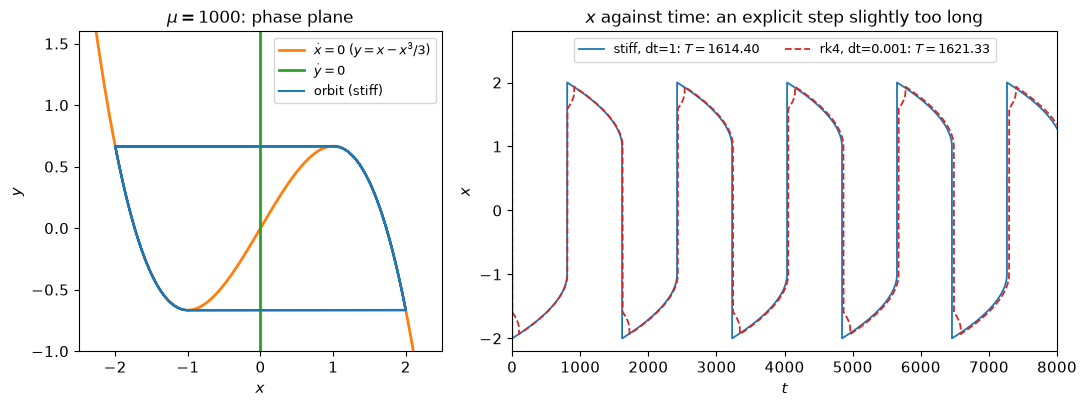

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
xc = np.linspace(-2.5, 2.5, 400)
a1.plot(xc, xc - xc**3 / 3, color="tab:orange", lw=2, label=r"$\dot x = 0$ ($y = x - x^3/3$)")
a1.axvline(0, color="tab:green", lw=2, label=r"$\dot y = 0$")
late = runs["stiff, dt=1"].t > 1000
a1.plot(runs["stiff, dt=1"]["x"][late], runs["stiff, dt=1"]["y"][late], color="tab:blue", lw=1.5,
        label="orbit (stiff)")
a1.set(xlim=(-2.5, 2.5), ylim=(-1, 1.6), xlabel="$x$", ylabel="$y$", title=r"$\mu = 1000$: phase plane")
a1.legend(loc="upper right")
for label, col, ls in [("stiff, dt=1", "tab:blue", "-"), ("rk4, dt=0.001", "tab:red", "--")]:
    tr = runs[label]
    a2.plot(tr.t, tr["x"], color=col, ls=ls, lw=1.3, label=f"{label}: $T = {periods[label]:.2f}$")
a2.set(xlim=(0, 8000), ylim=(-2.2, 2.8), xlabel="$t$", ylabel="$x$",
       title="$x$ against time: an explicit step slightly too long")
a2.legend(loc="upper center", ncol=2)
fig.tight_layout()
fig.savefig(FIG / "relaxation_cycle.png")

### Period against $\mu$

For 17 values of $\mu$ from 0.1 to 1000 (CVODE, run length from a rough guess
of the period): the period from crossing times, and from XPP's
*Initialconds → Periodic* up to $\mu = 200$ (beyond that, Periodic reports the
orbit is too stiff). The theory:

$$
T \approx 2\pi\Bigl(1 + \frac{\mu^2}{16}\Bigr) \;\; (\mu \ll 1), \qquad
T \approx (3 - 2\ln 2)\,\mu + 3\alpha\,\mu^{-1/3} \;\; (\mu \gg 1),
$$

where $\alpha = 2.338107$ is the first zero of $\operatorname{Ai}(-z)$.

  mu =    0.100   T (crossings) =     6.2871   T (Periodic) =     6.2871
  mu =    0.178   T (crossings) =     6.2956   T (Periodic) =     6.2956
  mu =    0.316   T (crossings) =     6.3223   T (Periodic) =     6.3223
  mu =    0.562   T (crossings) =     6.4063   T (Periodic) =     6.4063
  mu =    1.000   T (crossings) =     6.6633   T (Periodic) =     6.6633
  mu =    1.778   T (crossings) =     7.3839   T (Periodic) =     7.3839
  mu =    3.162   T (crossings) =     9.0713   T (Periodic) =     9.0713
  mu =    5.623   T (crossings) =    12.5121   T (Periodic) =    12.5121
  mu =   10.000   T (crossings) =    19.0784   T (Periodic) =    19.0784
  mu =   17.783   T (crossings) =    31.1893   T (Periodic) =    31.1893
  mu =   31.623   T (crossings) =    53.1285   T (Periodic) =    53.1285
  mu =   56.234   T (crossings) =    92.5030   T (Periodic) =    92.5030
  mu =  100.000   T (crossings) =   162.8371   T (Periodic) =   162.8371
  mu =  177.828   T (crossings) =   288.1821   T (P

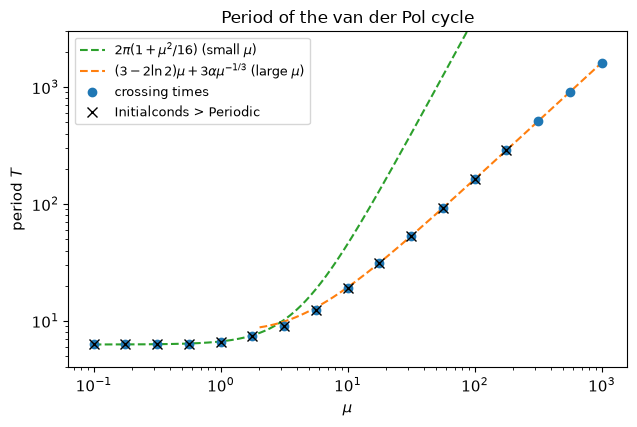

In [25]:
mus = np.logspace(-1, 3, 17)
T_cross, T_per = [], []
for mu in mus:
    Tg = 2 * np.pi if mu < 1 else max(2 * np.pi, 1.61 * mu)
    tr = m.run(keep=False, mu=mu, x=2, y=0.6667, meth="cvode", tol=1e-10, atol=1e-10,
               dt=Tg / 2000, total=8 * Tg, trans=2 * Tg)
    T_cross.append(period_from_crossings(tr))
    T_per.append(np.nan)
    if mu <= 200:
        m.run(mu=mu, x=2, y=0.6667, meth="cvode", tol=1e-10, atol=1e-10, dt=Tg / 1000, total=6 * Tg, trans=0)
        m.buttons.initialconds.periodic()
        T_per[-1] = m.numerics["total"]
m.set(mu=1000, x=2, y=0.6667, meth="stiff", dt=20, total=4000, tol=1e-6)
T_cross, T_per = np.array(T_cross), np.array(T_per)

ALPHA = 2.338107
mm = np.logspace(-1, 3, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.loglog(mm, 2 * np.pi * (1 + mm**2 / 16) * np.ones_like(mm), color="tab:green", ls="--",
          label=r"$2\pi(1 + \mu^2/16)$ (small $\mu$)")
ax.loglog(mm[mm > 2], (3 - 2 * np.log(2)) * mm[mm > 2] + 3 * ALPHA * mm[mm > 2] ** (-1 / 3),
          color="tab:orange", ls="--", label=r"$(3 - 2\ln 2)\mu + 3\alpha\mu^{-1/3}$ (large $\mu$)")
ax.loglog(mus, T_cross, "o", color="tab:blue", ms=6, label="crossing times")
ax.loglog(mus, T_per, "x", color="k", ms=7, label="Initialconds > Periodic")
ax.set(xlabel=r"$\mu$", ylabel="period $T$", ylim=(4, 3000), title="Period of the van der Pol cycle")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "period_vs_mu.png")
for mu, a, b in zip(mus, T_cross, T_per):
    print(f"  mu = {mu:8.3f}   T (crossings) = {a:10.4f}   T (Periodic) = {b:10.4f}")

### Checks

* Slow branch: $dy/dt = x/\mu$ and $dy = (1 - x^2)\,dx$, so
  $dt = \mu\,(1 - x^2)/x\,dx$. From $x = 2$ to the knee $x = 1$ this takes
  $\mu\,(3/2 - \ln 2)$; two branches give $T_0 = (3 - 2\ln 2)\,\mu$. The next
  term, from passing the knee, is $3\alpha\mu^{-1/3}$; the rest is
  $O(\ln\mu/\mu)$, about 0.007 here. The stiff solver's period at
  $\mu = 1000$ is checked against

$$
T = (3 - 2\ln 2)\,\mu + 3\alpha\,\mu^{-1/3}.
$$

* CVODE and RK4 with $dt = 0.0005$ agree with the stiff solver.
* Poincaré–Lindstedt: $T = 2\pi(1 + \mu^2/16 + O(\mu^4))$; at $\mu = 0.1$ the
  $O(\mu^4)$ term is about $10^{-6}$.
* At $\mu = 1$ the period is 6.663287 (literature); Periodic and crossing
  times agree at $\mu = 100$.

In [26]:
T_asym = (3 - 2 * np.log(2)) * 1000 + 3 * ALPHA * 1000 ** (-1 / 3)
check("period at mu = 1000, stiff vs asymptotics", periods["stiff, dt=1"], T_asym, 0.02)
check("cvode agrees with stiff (period)", periods["cvode, dt=1"], periods["stiff, dt=1"], 1e-3)
check("rk4 dt=0.0005 agrees with stiff (period)", periods["rk4, dt=0.0005"], periods["stiff, dt=1"], 1e-3)
check("period at mu = 0.1 vs 2*pi(1 + mu^2/16)", T_per[0], 2 * np.pi * (1 + 0.01 / 16), 1e-4)
check("period at mu = 1 (literature 6.663287)", T_per[np.isclose(mus, 1)][0], 6.663287, 1e-5)
check("Periodic and crossing times agree at mu = 100", T_per[np.isclose(mus, 100)][0], T_cross[np.isclose(mus, 100)][0], 1e-3)
checks_done()

  ok   period at mu = 1000, stiff vs asymptotics: 1614.4 (expected 1614.41)
  ok   cvode agrees with stiff (period): 1614.4 (expected 1614.4)
  ok   rk4 dt=0.0005 agrees with stiff (period): 1614.4 (expected 1614.4)
  ok   period at mu = 0.1 vs 2*pi(1 + mu^2/16): 6.28711 (expected 6.28711)
  ok   period at mu = 1 (literature 6.663287): 6.66329 (expected 6.66329)
  ok   Periodic and crossing times agree at mu = 100: 162.837 (expected 162.837)

11_stiff-van-der-pol: 6/6 checks passed


<a id="driven-pendulum"></a>
## 12. Damped driven pendulum: resting or rotating

A pendulum with damping $b$ driven by a constant torque $i$:

$$
\dot\theta = v, \qquad \dot v = i - b\,v - \sin\theta,
$$

with $b = 0.3$ and first $i = 0.5$. The angle $\theta$ lives on a circle, so
the phase space is a cylinder and XPP folds $\theta$ into $[0, 2\pi)$. Rest
states need $\sin\theta = i$, so they exist only for $i < 1$; a rotating orbit
exists for $i$ above a smaller value, and in between the pendulum may rest or
rotate depending on its history. The same equation describes a Josephson
junction and a phase-locked loop.

We find the two rest states, draw the cylinder with trajectories coloured by
where they end, and sweep $i$ up and down to see a hysteresis loop between
resting and rotating.

In [27]:
section("12_driven-pendulum")

### The model

`fold="th"` with `tor_per` $= 2\pi$ makes $\theta$ an angle. Three helpers:
`broken` puts NaN where the fold wraps $\theta$ (so plotted lines don't cross
the picture), `wraps` finds where $\theta$ passes $2\pi$ (the pendulum goes
over the top), and `mean_velocity` averages $v$ over whole turns (0 if the
pendulum rests).

In [28]:
TWO_PI = 2 * np.pi


def broken(th):
    th = np.asarray(th, float).copy()
    th[1:][np.abs(np.diff(th)) > np.pi] = np.nan
    return th


def wraps(tr):
    return np.where(np.diff(tr["th"]) < -np.pi)[0]


def mean_velocity(tr):
    w = wraps(tr)
    return tr["v"][w[0] + 1:w[-1] + 1].mean() if len(w) >= 2 else 0.0


mb = (ModelBuilder("driven_pendulum")
      .comment("damped driven pendulum; th is an angle")
      .ode("th", "v")
      .ode("v", "i-b*v-sin(th)")
      .parameter(i=0.5, b=0.3)
      .initial(th=0, v=2.5)
      .option(fold="th", tor_per=6.283185307, total=100, dt=0.05))
print(mb.render())
m = mb.load(ODE)
i0, b = 0.5, 0.3

# damped driven pendulum; th is an angle
th'=v
v'=i-b*v-sin(th)
par i=0.5,b=0.3
init th=0,v=2.5
@ fold=th,tor_per=6.283185307,total=100,dt=0.05
done



### Rest states at $i = 0.5$

XPP's Jacobian is a forward difference with relative step `jac_eps` (default
$10^{-3}$, the same number as the Newton tolerance), which puts errors of
about $10^{-4}$ into the eigenvalues; we use $10^{-7}$. A stable node and a
saddle; at $i = 1.2$ Newton finds no rest state at all (pyxpp raises an error).

In [29]:
m.set_option("jac_eps", 1e-7)
node = m.equilibrium({"th": 0.5, "v": 0})
saddle = m.equilibrium({"th": 2.6, "v": 0})
print("rest states at i = 0.5:")
for e in (node, saddle):
    print(" ", e, " eigenvalues", np.round(e.eigenvalues, 5))
m.set(i=1.2)
try:
    m.equilibrium({"th": 1.5, "v": 0})
    print("  at i = 1.2 Newton found a rest state (unexpected)")
except Exception as err:
    print("  at i = 1.2:", err)
m.set(i=i0)

rest states at i = 0.5:
  <Equilibrium stable TH=0.523599, V=0>  eigenvalues [-0.14988+0.91846j -0.14988-0.91846j]
  <Equilibrium unstable TH=2.61799, V=0>  eigenvalues [ 0.79272+0.j -1.09248+0.j]


  at i = 1.2: equilibrium not found (ierr=1)


<pyxpp.Model 12_driven-pendulum.ode: vars=['TH', 'V'] aux=[] pars=2>

### The cylinder at $i = 0.5$: rest or rotate?

Trajectories from 24 starts, red if still moving at the end, blue if they come
to rest; the rotating orbit (dark red) and the two rest states.

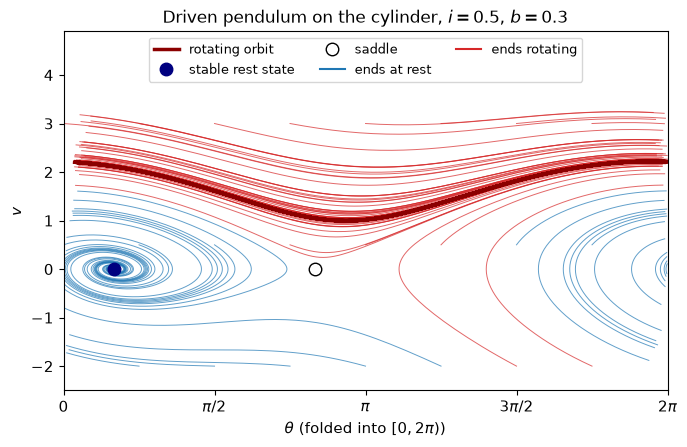

In [30]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for th0 in np.linspace(0, TWO_PI, 9)[:-1]:
    for v0 in (-2.0, 0.5, 3.0):
        tr = m.run(keep=False, th=th0, v=v0, total=60)
        col = "tab:red" if tr["v"][-100:].min() > 0.1 else "tab:blue"
        ax.plot(broken(tr["th"]), tr["v"], color=col, lw=0.7, alpha=0.7)
cyc = m.run(keep=False, th=0, v=2.5, total=200, trans=150)
ax.plot(broken(cyc["th"]), cyc["v"], color="darkred", lw=2.5, label="rotating orbit")
ax.plot(node.x["TH"], 0, "o", color="navy", ms=9, label="stable rest state")
ax.plot(saddle.x["TH"], 0, "o", mfc="white", mec="k", ms=9, label="saddle")
ax.plot([], [], color="tab:blue", label="ends at rest")
ax.plot([], [], color="tab:red", label="ends rotating")
ax.set(xlim=(0, TWO_PI), ylim=(-2.5, 4.9), xlabel=r"$\theta$ (folded into $[0, 2\pi)$)", ylabel="$v$",
       title=f"Driven pendulum on the cylinder, $i = {i0}$, $b = {b}$")
ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, TWO_PI], ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
fig.savefig(FIG / "cylinder.png")

### Hysteresis: sweep $i$ up, then down

Start at rest at $i = 0$; for each $i$ settle for 300 time units, continuing
from the last state, then measure the mean velocity over the next 300. Going
up, the pendulum stays at rest until the rest states vanish at $i = 1$; going
down, it keeps rotating to a much smaller $i$.

up sweep starts rotating at i = 1.0; down sweep stops below i = 0.375


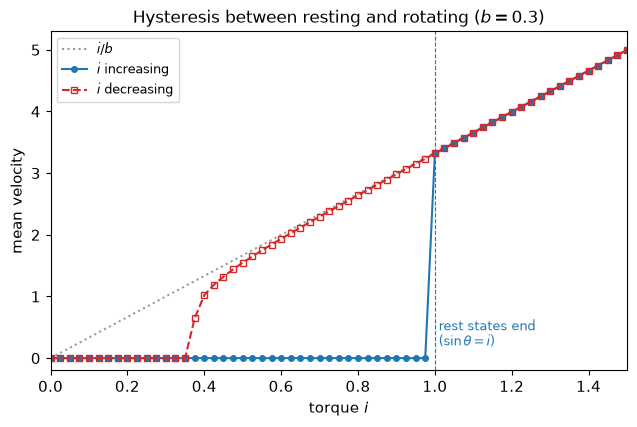

In [31]:
I = np.round(np.arange(0, 1.5001, 0.025), 4)
m.run(keep=False, i=0, th=0, v=0, total=10)
up, down = [], []
for sweep, values in ((up, I), (down, I[::-1])):
    for x in values:
        m.set(i=x)
        m.run_last(total=300)
        sweep.append(mean_velocity(m.run_last(total=300)))
up, down = np.array(up), np.array(down)[::-1]
m.set(i=i0)
i_leave = I[np.argmax(up > 0)]
i_stop = I[np.argmax(down > 0)]
print(f"up sweep starts rotating at i = {i_leave}; down sweep stops below i = {i_stop}")

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.plot(I, I / b, color="0.6", ls=":", label="$i/b$")
ax.plot(I, up, "o-", color="tab:blue", ms=4, label="$i$ increasing")
ax.plot(I, down, "s--", color="tab:red", ms=4, mfc="none", label="$i$ decreasing")
ax.axvline(1, color="tab:blue", lw=0.8, ls="--")
ax.text(1.01, 0.2, "rest states end\n" r"($\sin\theta = i$)", fontsize=9, color="tab:blue")
ax.set(xlim=(0, 1.5), ylim=(-0.2, 5.3), xlabel="torque $i$", ylabel="mean velocity",
       title=f"Hysteresis between resting and rotating ($b = {b}$)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "hysteresis.png")

### Checks

* Rest states: $\theta = \arcsin i$ (node) and $\theta = \pi - \arcsin i$
  (saddle). Linearising at a rest state gives
  $\lambda^2 + b\lambda + \cos\theta = 0$, so $\lambda_1\lambda_2 = \cos\theta$:
  $+\cos(\arcsin i)$ at the node and $-\cos(\arcsin i)$ at the saddle.
* The up sweep leaves rest at $i = 1$ (on the grid of step 0.025).
* Melnikov: for small damping the rotating orbit is born in a homoclinic loop at

$$
i_{\mathrm{hom}} = \frac{4b}{\pi}\bigl(1 + O(b^2)\bigr);
$$

  at $b = 0.05$ we find it by bisection on whether the pendulum rotates.
* Over whole turns $\langle\dot v\rangle = 0$, so
  $b\langle v\rangle = i - \langle\sin\theta\rangle$. For fast rotation
  $\theta \approx Wt$, and to second order
  $\langle\sin\theta\rangle = b/\bigl(2W(W^2 + b^2)\bigr)$, so

$$
\langle v\rangle = \frac{i}{b} - \frac{1}{2W(W^2 + b^2)}, \qquad W = \frac{i}{b},
$$

  checked at $i = 1.5$; both sweeps agree there.

In [32]:
def rotates(i, bb):
    tr = m.run(keep=False, i=i, b=bb, th=0, v=i / bb + 1, total=600, trans=400, dt=0.02)
    return len(wraps(tr)) >= 2


check("stable rest state th = arcsin(i) (exact)", node.x["TH"], np.arcsin(i0), 1e-6)
check("saddle th = pi - arcsin(i) (exact)", saddle.x["TH"], np.pi - np.arcsin(i0), 1e-6)
check("node: eigenvalue product = cos th (exact)", np.prod(node.eigenvalues).real, np.cos(np.arcsin(i0)), 1e-6)
check("saddle: eigenvalue product = -cos th (exact)", np.prod(saddle.eigenvalues).real,
      -np.cos(np.arcsin(i0)), 1e-6)
check("up sweep leaves rest at i = 1 (grid 0.025)", i_leave, 1.0, 0.025)
bb, lo, hi = 0.05, 0.02, 0.1
for _ in range(18):
    lo, hi = (lo, (lo + hi) / 2) if rotates((lo + hi) / 2, bb) else ((lo + hi) / 2, hi)
check("homoclinic torque / (4b/pi) at b = 0.05 (Melnikov)", hi / (4 * bb / np.pi), 1.0, bb**2)
W = 1.5 / b
check("mean velocity at i = 1.5 vs i/b - 1/(2W(W^2+b^2))", up[-1], W - 1 / (2 * W * (W**2 + b**2)), 2e-4)
check("up and down sweeps agree at i = 1.5", down[-1], up[-1], 1e-4)
checks_done()

  ok   stable rest state th = arcsin(i) (exact): 0.523599 (expected 0.523599)
  ok   saddle th = pi - arcsin(i) (exact): 2.61799 (expected 2.61799)
  ok   node: eigenvalue product = cos th (exact): 0.866025 (expected 0.866025)
  ok   saddle: eigenvalue product = -cos th (exact): -0.866025 (expected -0.866025)
  ok   up sweep leaves rest at i = 1 (grid 0.025): 1 (expected 1)


  ok   homoclinic torque / (4b/pi) at b = 0.05 (Melnikov): 0.999384 (expected 1)
  ok   mean velocity at i = 1.5 vs i/b - 1/(2W(W^2+b^2)): 4.99603 (expected 4.99601)
  ok   up and down sweeps agree at i = 1.5: 4.996 (expected 4.99603)

12_driven-pendulum: 8/8 checks passed


<a id="delayed-logistic-map"></a>
## 13. Delayed logistic map: a Neimark–Sacker bifurcation

$$
x_{n+1} = y_n, \qquad y_{n+1} = a\,y_n\,(1 - x_n):
$$

a logistic map whose growth depends on the previous generation too. Its fixed
point $x = y = 1 - 1/a$ is stable up to $a = 2$, where a complex pair of
multipliers leaves the unit circle. Instead of a period doubling, an
invariant closed curve is born (a *Neimark–Sacker* bifurcation, the map
version of a Hopf bifurcation), and orbits turn around it about once every six
iterates.

We compute the multipliers with XPP for several $a$, find the crossing with
AUTO, and measure the size of the invariant curve and the rotation number on
it. Look at $a = 2.2$: there the orbit has locked onto a cycle of period 7.

In [33]:
section("13_delayed-logistic-map")

### The model

In [34]:
mb = (ModelBuilder("delayed_logistic_map")
      .comment("delayed logistic map")
      .map("x", "y")
      .map("y", "a*y*(1-x)")
      .parameter(a=2.1)
      .initial(x=0.6, y=0.6)
      .option(total=4000, meth="discrete"))
print(mb.render())
m = mb.load(ODE)

# delayed logistic map
x(t+1)=y
y(t+1)=a*y*(1-x)
par a=2.1
init x=0.6,y=0.6
@ total=4000,meth=discrete
done



### The fixed point and its multipliers

The Jacobian at the fixed point is

$$
J = \begin{pmatrix} 0 & 1 \\ -a y & a(1 - x) \end{pmatrix}
  = \begin{pmatrix} 0 & 1 \\ -(a - 1) & 1 \end{pmatrix},
$$

with trace 1 and determinant $a - 1$. For $a > 5/4$ the multipliers are a
complex pair with $|\lambda|^2 = \det J = a - 1$, so $|\lambda| = \sqrt{a - 1}$
passes 1 at $a = 2$, where $\cos(\arg\lambda) = \operatorname{tr}J/(2|\lambda|)
= 1/2$, i.e. $\arg\lambda = \pi/3$: one sixth of a turn.

In [35]:
A = np.linspace(1.3, 2.3, 21)
mods = []
for a in A:
    m.pars["a"] = a
    e = m.equilibrium({"x": 1 - 1 / a, "y": 1 - 1 / a})
    mods.append(np.abs(e.eigenvalues).max())
m.pars["a"] = 2.1
e21 = m.equilibrium({"x": 0.5, "y": 0.5})
print("a = 2.1: fixed point", e21.x, "multipliers", np.round(e21.eigenvalues, 6))

a = 2.1: fixed point {'X': 0.5238095238233729, 'Y': 0.5238095238233729} multipliers [0.5+0.921954j 0.5-0.921954j]


### AUTO: where the fixed point loses stability

Start AUTO from the fixed point reached at $a = 1.9$. For a map, HB marks
multipliers leaving the unit circle.

In [36]:
m.run(a=1.9, x=0.4, y=0.4, total=2000)
m.run_last()
d = m.auto.run("a", start="steady", ds=0.01, dsmax=0.02, parmin=1.5, parmax=2.3, nmax=200, epss=1e-7)
ns = d.special("HB")[0]
mu = ns.eigenvalues[np.argmax(ns.eigenvalues.imag)]
print(f"AUTO: Neimark-Sacker at a = {ns.x:.7f}, multipliers {mu:.6f} and its conjugate")

AUTO: Neimark-Sacker at a = 2.0000000, multipliers 0.500000+0.866025j and its conjugate


### Orbits, size of the invariant curve, rotation number

`curve` returns an orbit on the invariant curve after a long transient;
`rotation` counts turns per iterate around the fixed point (the map turns
clockwise in $(x, y)$). The curve's half width in $x$ is measured for
$a - 2$ from 0.005 to 0.16 and its growth exponent fitted on the three
smallest; the rotation number is extrapolated linearly to $a = 2$.

curve size ~ (a-2)^0.4962; rotation numbers [0.16621 0.16573 0.16478] -> 0.16668 at a = 2


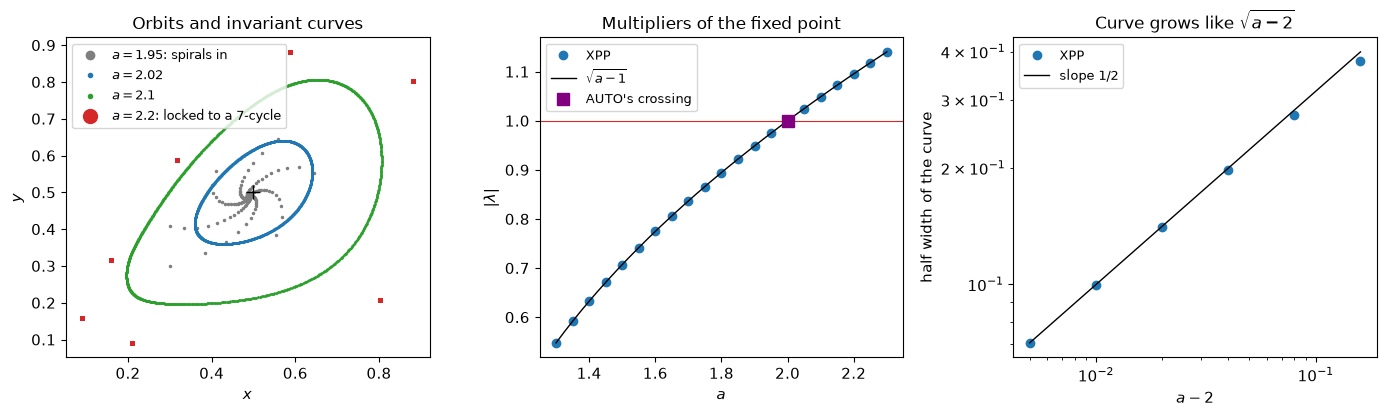

In [37]:
def curve(a, n=4000, trans=30000):
    tr = m.run(keep=False, a=a, x=0.55, y=0.55, total=trans + n, trans=trans)
    return tr["x"], tr["y"]


def rotation(a):
    x, y = curve(a)
    th = np.unwrap(np.arctan2(y - (1 - 1 / a), x - (1 - 1 / a)))
    return -(th[-1] - th[0]) / (2 * np.pi * (len(th) - 1))


da = np.array([0.005, 0.01, 0.02, 0.04, 0.08, 0.16])
size = np.array([np.ptp(curve(2 + s)[0]) / 2 for s in da])
slope = np.polyfit(np.log(da[:3]), np.log(size[:3]), 1)[0]
rot = np.array([rotation(2 + s) for s in da[:3]])
rot0 = np.polyval(np.polyfit(da[:3], rot, 1), 0)
print(f"curve size ~ (a-2)^{slope:.4f}; rotation numbers {np.round(rot, 5)} -> {rot0:.5f} at a = 2")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
tr = m.run(keep=False, a=1.95, x=0.3, y=0.3, total=300)
axs[0].plot(tr["x"], tr["y"], ".", ms=3, color="tab:gray", label="$a = 1.95$: spirals in")
for a, col, lab in zip((2.02, 2.1, 2.2), ("tab:blue", "tab:green", "tab:red"), ("", "", ": locked to a 7-cycle")):
    axs[0].plot(*curve(a, n=1500), ".", ms=1.5 if a < 2.2 else 5, color=col, label=f"$a = {a}${lab}")
axs[0].plot(0.5, 0.5, "k+", ms=10)
axs[0].set(xlabel="$x$", ylabel="$y$", title="Orbits and invariant curves")
axs[0].legend(markerscale=4)
Af = np.linspace(1.3, 2.3, 200)
axs[1].plot(A, mods, "o", label="XPP")
axs[1].plot(Af, np.sqrt(Af - 1), "k-", lw=1, label=r"$\sqrt{a - 1}$")
axs[1].axhline(1, color="tab:red", lw=0.8)
axs[1].plot(ns.x, 1, "s", color="purple", ms=8, label="AUTO's crossing")
axs[1].set(xlabel="$a$", ylabel=r"$|\lambda|$", title="Multipliers of the fixed point")
axs[1].legend()
axs[2].loglog(da, size, "o", label="XPP")
axs[2].loglog(da, size[0] * np.sqrt(da / da[0]), "k-", lw=1, label="slope 1/2")
axs[2].set(xlabel="$a - 2$", ylabel="half width of the curve", title=r"Curve grows like $\sqrt{a - 2}$")
axs[2].legend()
fig.tight_layout()
fig.savefig(FIG / "neimark_sacker.png")

### Checks

* The fixed point $x = 1 - 1/a$ at $a = 2.1$, and $|\lambda| = \sqrt{a - 1}$
  at all 21 values of $a$.
* AUTO: the multipliers cross the unit circle at $a = 2$, with
  $|\lambda| = 1$ and $\arg\lambda = \pi/3$ there.
* On the invariant curve the rotation number tends to $1/6$ as $a \to 2$.
* The normal form of the Neimark–Sacker bifurcation predicts a curve of size
  $\propto (a - 2)^{1/2}$.

In [38]:
check("fixed point x at a = 2.1, 1 - 1/a (exact)", e21.x["X"], 1 - 1 / 2.1, 1e-9)
check("largest error in |multiplier| vs sqrt(a - 1) (exact 0)", np.max(np.abs(mods - np.sqrt(A - 1))), 0, 1e-9)
check("AUTO: multipliers cross the unit circle at a = 2 (exact)", ns.x, 2.0, 1e-6)
check("AUTO: |multiplier| there (exact 1)", abs(mu), 1.0, 1e-6)
check("AUTO: arg multiplier there, pi/3 (exact)", np.angle(mu), np.pi / 3, 1e-6)
check("rotation number on the curve extrapolated to a = 2, 1/6 (exact)", rot0, 1 / 6, 5e-4)
check("size of the curve ~ (a - 2)^p, p (normal form 1/2)", slope, 0.5, 0.02)
checks_done()

  ok   fixed point x at a = 2.1, 1 - 1/a (exact): 0.52381 (expected 0.52381)
  ok   largest error in |multiplier| vs sqrt(a - 1) (exact 0): 1.03251e-13 (expected 0)
  ok   AUTO: multipliers cross the unit circle at a = 2 (exact): 2 (expected 2)
  ok   AUTO: |multiplier| there (exact 1): 1 (expected 1)
  ok   AUTO: arg multiplier there, pi/3 (exact): 1.0472 (expected 1.0472)
  ok   rotation number on the curve extrapolated to a = 2, 1/6 (exact): 0.166679 (expected 0.166667)
  ok   size of the curve ~ (a - 2)^p, p (normal form 1/2): 0.496245 (expected 0.5)

13_delayed-logistic-map: 7/7 checks passed


<a id="rossler"></a>
## 14. The Rössler system: period doubling to chaos

$$
\dot x = -y - z, \qquad \dot y = x + a\,y, \qquad \dot z = b + z\,(x - c),
$$

with $a = b = 0.2$ and first $c = 5.7$. A simpler chaotic flow than Lorenz's,
with one nonlinear term ($zx$). The orbit winds around an unstable spiral near
the origin and is now and then thrown up in $z$ and folded back. As $c$ grows
the periodic orbit doubles its period again and again, and at $c = 5.7$ the
flow is chaotic.

We find both equilibria (one with Newton's method, both with AUTO), draw
orbits of period 1, 2, 4 and chaos, plot the maxima of $x$ against $c$, and
locate the first two period doublings.

In [39]:
section("14_rossler")

### The model

`maxima` returns the local maxima of a time series.

In [40]:
def maxima(x):
    k = np.where((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:]))[0] + 1
    return x[k]


a, b, c = 0.2, 0.2, 5.7
mb = (ModelBuilder("rossler")
      .comment("Rossler system")
      .ode("x", "-y-z")
      .ode("y", "x+a*y")
      .ode("z", "b+z*(x-c)")
      .parameter(a=a, b=b, c=c)
      .initial(x=1, y=1, z=0)
      .option(total=300, dt=0.02, meth="rk4", bound=1000))
print(mb.render())
m = mb.load(ODE)

# Rossler system
x'=-y-z
y'=x+a*y
z'=b+z*(x-c)
par a=0.2,b=0.2,c=5.7
init x=1,y=1,z=0
@ total=300,dt=0.02,meth=rungekutta,bound=1000
done



### Equilibria: Newton for the inner one, AUTO for both

The outer equilibrium has one unstable real direction, and `m.equilibrium`
reports it as not found: XPP's Newton step converges, but the extra step that
computes the eigenvector of that direction gives up, and its error flag comes
back as a failure. So we reach it with AUTO: start on the inner equilibrium,
follow it down in $c$ through the fold where the two equilibria are born, and
up the outer branch to $c = 5.7$ (AUTO stops just past it).

In [41]:
inner = m.equilibrium({"x": 0, "y": 0, "z": 0})
print("inner equilibrium:", inner, "\n  eigenvalues:", np.round(inner.eigenvalues, 4))
m.set(x=inner.x["X"], y=inner.x["Y"], z=inner.x["Z"])
eqs = m.auto.run("c", start="steady", ds=-0.02, dsmax=0.1, parmin=0.2, parmax=c, nmax=600)
fold = eqs.special("LP")[0]
outer = eqs[-1]
print(f"AUTO: fold at c = {fold.x:.6f}; outer equilibrium at c = {outer.x:.4f}:",
      {k: round(v, 5) for k, v in outer.u0.items()})
m.set(x=1, y=1, z=0, c=c)

inner equilibrium: <Equilibrium unstable X=0.0070262, Y=-0.035131, Z=0.035131> 
  eigenvalues: [ 0.097+0.9952j  0.097-0.9952j -5.687+0.j    ]


AUTO: fold at c = 0.400000; outer equilibrium at c = 5.7016: {'X': np.float64(5.69461), 'Y': np.float64(-28.47305), 'Z': np.float64(28.47305)}


<pyxpp.Model 14_rossler.ode: vars=['X', 'Y', 'Z'] aux=[] pars=3>

### Orbits at four values of $c$

Period 1, 2, 4 and chaos, projected on $(x, y)$, and the attractor at
$c = 5.7$ in 3-D.

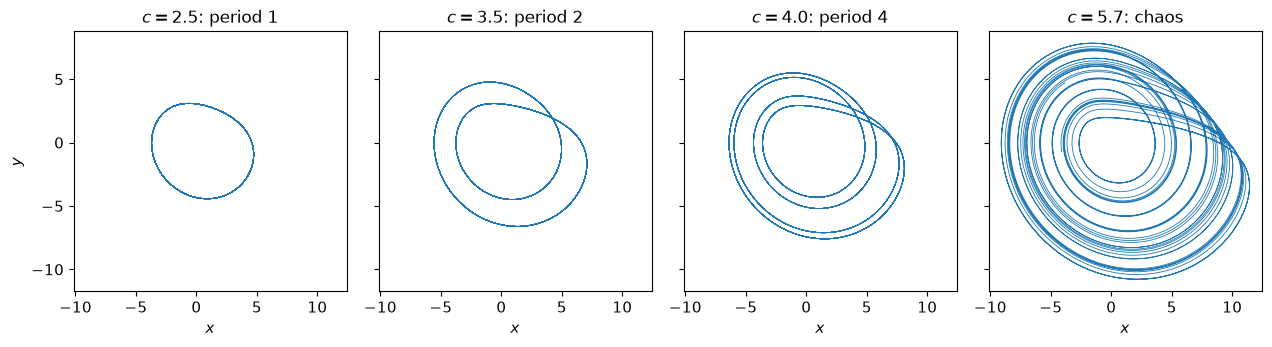

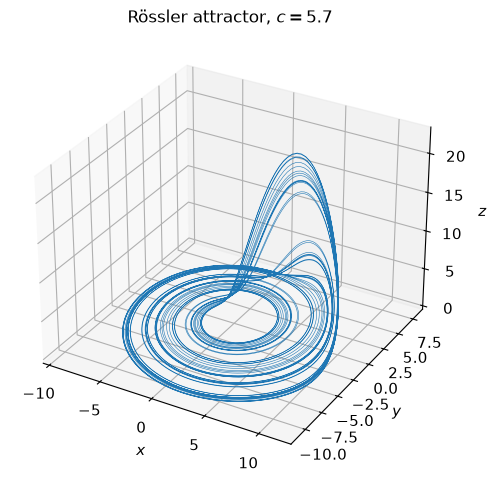

In [42]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, cc, lab in zip(axs, (2.5, 3.5, 4.0, 5.7), ("period 1", "period 2", "period 4", "chaos")):
    tr = m.run(keep=False, c=cc, total=700, trans=500)
    ax.plot(tr["x"], tr["y"], lw=0.6)
    ax.set(title=f"$c = {cc}$: {lab}", xlabel="$x$")
axs[0].set_ylabel("$y$")
fig.tight_layout()
fig.savefig(FIG / "orbits.png")

tr = m.run(keep=False, total=500, trans=200)
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.plot(tr["x"], tr["y"], tr["z"], lw=0.4)
ax.set(xlabel="$x$", ylabel="$y$", zlabel="$z$", title="Rössler attractor, $c = 5.7$")
fig.tight_layout()
fig.savefig(FIG / "attractor.png")

### Maxima of $x$ against $c$

The maxima of $x$ after transients, for 226 values of $c$: one value per $c$
on a period-1 orbit, two on period 2, and so on.

In [43]:
C, M = [], []
for cc in np.linspace(2, 6.5, 226):
    mx = maxima(m.run(keep=False, c=cc, total=800, trans=500)["x"])
    C += [cc] * len(mx)
    M += list(mx)

### Where the period doubles

Just past a period doubling the maxima alternate, and the gap between them
grows like $\sqrt{c - c_{\mathrm{PD}}}$. So the squared gap is linear in $c$:
fit it and extrapolate to zero. For the first doubling compare maxima one
apart, for the second two apart. The doublings are marked on the diagram.

period doublings at c = 2.8318 and 3.8363


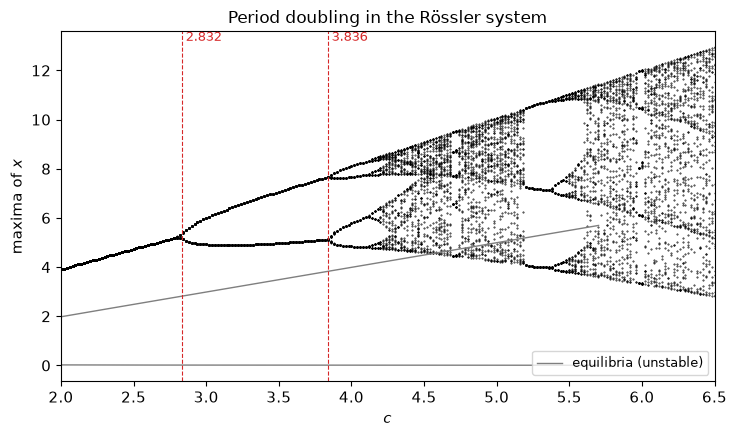

In [44]:
def gap(cc, lag):
    mx = maxima(m.run(keep=False, c=cc, total=3000, trans=2500)["x"])[-20:]
    return np.mean(np.abs(mx[lag:] - mx[:-lag]))


c_pd = []
for lag, cs in ((1, np.linspace(2.86, 2.98, 7)), (2, np.linspace(3.87, 3.95, 5))):
    g2 = np.array([gap(cc, lag)**2 for cc in cs])
    slope, icept = np.polyfit(cs, g2, 1)
    c_pd.append(-icept / slope)
print(f"period doublings at c = {c_pd[0]:.4f} and {c_pd[1]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(C, M, "k.", ms=0.8)
ax.plot([p.x for p in eqs], [p.u0["x"] for p in eqs], color="tab:gray", lw=1,
        label="equilibria (unstable)")
ax.legend(loc="lower right")
ax.set(xlim=(2, 6.5), xlabel="$c$", ylabel="maxima of $x$", title="Period doubling in the Rössler system")
for cp in c_pd:
    ax.axvline(cp, color="tab:red", lw=0.8, ls="--")
ax.text(c_pd[0], ax.get_ylim()[1], f" {c_pd[0]:.3f}", color="tab:red", va="top", fontsize=9)
ax.text(c_pd[1], ax.get_ylim()[1], f" {c_pd[1]:.3f}", color="tab:red", va="top", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "maxima_vs_c.png")

### Checks

$\dot x = 0$ gives $z = -y$, $\dot y = 0$ gives $y = -x/a$, so $z = x/a$, and
$\dot z = 0$ gives $x^2 - cx + ab = 0$:

$$
x_\mp = \frac{c \mp \sqrt{c^2 - 4ab}}{2}, \qquad y = -\frac{x}{a}, \qquad z = \frac{x}{a}.
$$

The inner ($-$) and outer ($+$) equilibria meet in a fold at
$c = 2\sqrt{ab}$. In the literature (for $a = b = 0.2$) the first two period
doublings are at $c = 2.83$ and $3.84$.

In [45]:
def x_eq(cc, sign):
    return (cc + sign * np.sqrt(cc**2 - 4 * a * b)) / 2


check("inner equilibrium x (exact)", inner.x["X"], x_eq(c, -1), 1e-8)
check("inner equilibrium y = -x/a (exact)", inner.x["Y"], -x_eq(c, -1) / a, 1e-7)
check("inner equilibrium z = x/a (exact)", inner.x["Z"], x_eq(c, -1) / a, 1e-7)
check("outer equilibrium x (exact, at AUTO's c)", outer.u0["x"], x_eq(outer.x, 1), 1e-6)
check("outer equilibrium z = x/a (exact)", outer.u0["z"], outer.u0["x"] / a, 1e-6)
check("fold of equilibria at c = 2 sqrt(ab) (exact)", fold.x, 2 * np.sqrt(a * b), 1e-6)
check("first period doubling (literature 2.83)", c_pd[0], 2.83, 0.02)
check("second period doubling (literature 3.84)", c_pd[1], 3.84, 0.02)
checks_done()

  ok   inner equilibrium x (exact): 0.0070262 (expected 0.0070262)
  ok   inner equilibrium y = -x/a (exact): -0.035131 (expected -0.035131)
  ok   inner equilibrium z = x/a (exact): 0.035131 (expected 0.035131)
  ok   outer equilibrium x (exact, at AUTO's c): 5.69461 (expected 5.69461)
  ok   outer equilibrium z = x/a (exact): 28.4731 (expected 28.4731)
  ok   fold of equilibria at c = 2 sqrt(ab) (exact): 0.4 (expected 0.4)
  ok   first period doubling (literature 2.83): 2.8318 (expected 2.83)
  ok   second period doubling (literature 3.84): 3.83631 (expected 3.84)

14_rossler: 8/8 checks passed


<a id="lorenz-84"></a>
## 15. Lorenz 84: a model of the atmosphere

Lorenz's 1984 low-order model of the general circulation: $x$ is the strength
of the westerly wind (the jet), $y$ and $z$ the cosine and sine phases of a
chain of travelling eddies,

$$
\dot x = -y^2 - z^2 - a\,x + a\,F, \qquad
\dot y = x y - b\,x z - y + G, \qquad
\dot z = b\,x y + x z - z .
$$

$F$ is the thermal forcing of the jet and $G$ the forcing of the eddies. With
$a = 0.25$, $b = 4$, $G = 1$ the flow is chaotic at $F = 8$ and periodic at
$F = 6$; at small $F$ the steady westerly flow is stable.

We compare the chaotic and periodic flows, follow the steady flow in $F$ with
AUTO (two folds and a Hopf point), and then set $G = 0$, where the *Hadley
state* $x = F$, $y = z = 0$ loses stability in a Hopf bifurcation at $F = 1$.

In [46]:
section("15_lorenz-84")

### The model

The right-hand side and its Jacobian are also written in NumPy (`rhs`, `jac`),
to test AUTO's equilibria independently.

In [47]:
def rhs(u, p):
    x, y, z = u["x"], u["y"], u["z"]
    return np.array([-y**2 - z**2 - p["a"] * x + p["a"] * p["f"],
                     x * y - p["b"] * x * z - y + p["g"],
                     p["b"] * x * y + x * z - z])


def jac(u, p):
    x, y, z, a, b = u["x"], u["y"], u["z"], p["a"], p["b"]
    return np.array([[-a, -2 * y, -2 * z],
                     [y - b * z, x - 1, -b * x],
                     [b * y + z, b * x, x - 1]])


mb = (ModelBuilder("lorenz84")
      .comment("Lorenz 84 general circulation model")
      .ode("x", "-y^2-z^2-a*x+a*f")
      .ode("y", "x*y-b*x*z-y+g")
      .ode("z", "b*x*y+x*z-z")
      .parameter(a=0.25, b=4, f=8, g=1)
      .initial(x=1, y=0, z=0)
      .option(total=200, dt=0.02, trans=20))
print(mb.render())
m = mb.load(ODE)

# Lorenz 84 general circulation model
x'=-y^2-z^2-a*x+a*f
y'=x*y-b*x*z-y+g
z'=b*x*y+x*z-z
par a=0.25,b=4,f=8,g=1
init x=1,y=0,z=0
@ total=200,dt=0.02,trans=20
done



### Chaotic ($F = 8$) and periodic ($F = 6$) flow

The spread of the maxima of $x$ measures how regular the flow is: on a
periodic orbit the same maximum repeats every cycle, so the spread is 0.

F = 8: 112 maxima of x, spread 1.7543


F = 6: 43 maxima of x, spread 0.0002


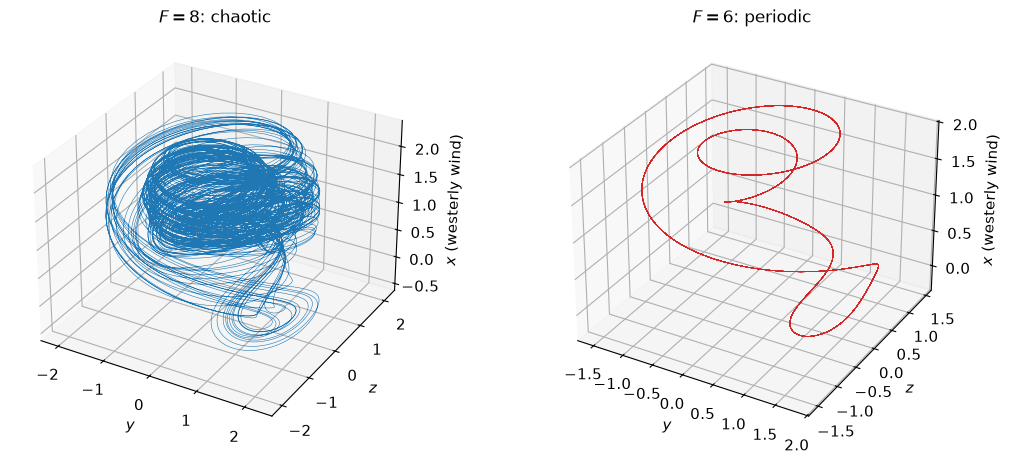

In [48]:
fig = plt.figure(figsize=(11, 4.8))
spread = {}
for k, (F, col) in enumerate(((8, "tab:blue"), (6, "tab:red"))):
    tr = m.run(keep=False, f=F, total=600, trans=300)
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot(tr["y"], tr["z"], tr["x"], lw=0.4, color=col)
    ax.set(xlabel="$y$", ylabel="$z$", zlabel="$x$ (westerly wind)",
           title=f"$F = {F}$: {'chaotic' if F == 8 else 'periodic'}")
    x = tr["x"]
    mx = x[np.where((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:]))[0] + 1]
    spread[F] = np.ptp(mx)
    print(f"F = {F}: {len(mx)} maxima of x, spread {spread[F]:.4f}")
fig.tight_layout()
fig.savefig(FIG / "flows.png")

### AUTO: the steady flow in $F$ at $G = 1$

Settle on the stable steady flow at $F = 0.1$ and follow it. AUTO's
tolerances are tightened from their defaults so that the equilibria (and the
special points, located by AUTO's own iteration) satisfy the equations to
about $10^{-8}$. The branch has two folds and a Hopf point close together near
$F = 1.2$–$1.4$ (see the inset).

AUTO's default tolerances: {'epsl': 0.0001, 'epsu': 0.0001, 'epss': 0.0001}


AUTO, steady flow in F (G = 1):
  folds at F = [4.31208, 1.1888] ; Hopf at F = [1.27894]


  Hopf at F = 1.27894: l1 = -3.8207 (supercritical), period at onset 1.487


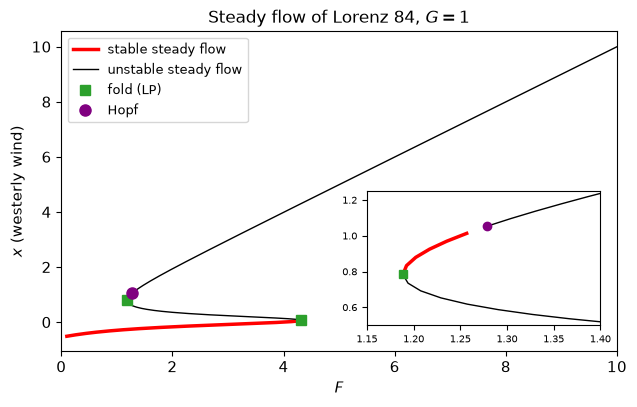

In [49]:
m.set(f=0.1, g=1)
m.run(total=500)
m.run_last(total=10)
print("AUTO's default tolerances:", {k: m.auto.settings[k] for k in ("epsl", "epsu", "epss")})
eqs = m.auto.run("f", start="steady", ds=0.01, dsmax=0.05, parmin=0, parmax=10, nmax=1000,
                 epsl=1e-8, epsu=1e-8, epss=1e-6)
lps, hbs = eqs.special("LP"), eqs.special("HB")
print("AUTO, steady flow in F (G = 1):")
print("  folds at F =", [round(p.x, 5) for p in lps], "; Hopf at F =", [round(p.x, 5) for p in hbs])
for p in hbs:
    l1, om = m.auto.lyapunov(p)
    print(f"  Hopf at F = {p.x:.5f}: l1 = {l1:+.4f} ({'sub' if l1 > 0 else 'super'}critical), "
          f"period at onset {2 * np.pi / om:.3f}")
resid = max(np.abs(rhs(p.u0, p.par)).max() for p in eqs)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
fs = np.array([p.x for p in eqs])
xs = np.array([p.u0["x"] for p in eqs])
st = np.array([p.stable for p in eqs])
ax.plot(fs, np.where(st, xs, np.nan), "r-", lw=2.5, label="stable steady flow")
ax.plot(fs, np.where(~st, xs, np.nan), "k-", lw=1, label="unstable steady flow")
ax.plot([p.x for p in lps], [p.u0["x"] for p in lps], "s", color="tab:green", ms=7, label="fold (LP)")
ax.plot([p.x for p in hbs], [p.u0["x"] for p in hbs], "o", color="purple", ms=8, label="Hopf")
ax.set(xlim=(0, 10), xlabel="$F$", ylabel="$x$ (westerly wind)", title="Steady flow of Lorenz 84, $G = 1$")
ax.legend(loc="upper left")
zoom = ax.inset_axes([0.55, 0.08, 0.42, 0.42])
zoom.plot(fs, np.where(st, xs, np.nan), "r-", lw=2.5)
zoom.plot(fs, np.where(~st, xs, np.nan), "k-", lw=1)
zoom.plot([p.x for p in lps], [p.u0["x"] for p in lps], "s", color="tab:green", ms=6)
zoom.plot([p.x for p in hbs], [p.u0["x"] for p in hbs], "o", color="purple", ms=6)
zoom.set(xlim=(1.15, 1.4), ylim=(0.5, 1.25))
zoom.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### $G = 0$: the Hadley circulation $x = F$, $y = z = 0$

Start exactly on the Hadley state and follow it in $F$. Note
`m.auto.reset()` before this second diagram: without it pyxpp drops the new
points, because XPP numbers them from zero again after discarding the old
diagram, and pyxpp keeps only points numbered after the old ones.

In [50]:
m.set(g=0, f=0.5, x=0.5, y=0, z=0)
m.run(total=50)
m.run_last(total=10)
m.auto.reset()
had = m.auto.run("f", start="steady", ds=0.01, dsmax=0.05, parmin=0, parmax=3, nmax=500)
hb0 = had.special("HB")[0]
l1, om0 = m.auto.lyapunov(hb0)
print(f"G = 0: Hadley state loses stability at F = {hb0.x:.6f}, frequency {om0:.5f}")
hadley_err = max(max(abs(p.u0["x"] - p.x), abs(p.u0["y"]), abs(p.u0["z"])) for p in had)

G = 0: Hadley state loses stability at F = 1.000000, frequency 4.00000


### Checks

* AUTO's steady flow satisfies the equations ($|\text{rhs}| \approx 0$ at every
  point).
* At a fold one eigenvalue of the Jacobian is 0; at a Hopf point a pair is
  $\pm i\omega$ (real part 0).
* The flow at $F = 6$ is periodic (spread 0) and at $F = 8$ chaotic (large
  spread).
* At $G = 0$, $y = z = 0$ gives $x = F$. The eddies there obey

$$
\dot y = (x - 1)\,y - b\,x\,z, \qquad \dot z = b\,x\,y + (x - 1)\,z,
$$

  with eigenvalues $(x - 1) \pm i\,bx$, so they grow once $x = F > 1$, with
  frequency $bF = 4$ at onset.

In [51]:
check("largest |right-hand side| on AUTO's steady flow (exact 0)", resid, 0, 1e-6)
for p in lps:
    check(f"smallest |eigenvalue| at the fold F = {p.x:.4f} (exact 0)",
          np.abs(np.linalg.eigvals(jac(p.u0, p.par))).min(), 0, 1e-5)
ev = np.linalg.eigvals(jac(hbs[0].u0, hbs[0].par))
pair = ev[np.argmax(np.abs(ev.imag))]
check("real part of the complex pair at the Hopf point (exact 0)", pair.real, 0, 1e-5)
check("spread of maxima of x at F = 6 (periodic: 0)", spread[6], 0, 1e-3)
check("spread of maxima of x at F = 8 is large (chaos: 1 = yes)", float(spread[8] > 0.5), 1, 0)
check("Hadley state is x = F, y = z = 0 along the branch", hadley_err, 0, 1e-8)
check("Hopf of the Hadley state at F = 1 (exact)", hb0.x, 1.0, 1e-6)
check("frequency at onset b*F = 4 (exact)", om0, 4.0, 1e-4)
checks_done()

  ok   largest |right-hand side| on AUTO's steady flow (exact 0): 4.9673e-12 (expected 0)
  ok   smallest |eigenvalue| at the fold F = 4.3121 (exact 0): 6.33591e-10 (expected 0)
  ok   smallest |eigenvalue| at the fold F = 1.1888 (exact 0): 5.37271e-07 (expected 0)
  ok   real part of the complex pair at the Hopf point (exact 0): 4.07425e-09 (expected 0)
  ok   spread of maxima of x at F = 6 (periodic: 0): 0.000194788 (expected 0)
  ok   spread of maxima of x at F = 8 is large (chaos: 1 = yes): 1 (expected 1)
  ok   Hadley state is x = F, y = z = 0 along the branch: 1.11022e-16 (expected 0)
  ok   Hopf of the Hadley state at F = 1 (exact): 1 (expected 1)
  ok   frequency at onset b*F = 4 (exact): 4 (expected 4)

15_lorenz-84: 9/9 checks passed


## Summary

All checks of this notebook:

In [52]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

08_wilson-cowan                            8/8
09_morris-lecar                            9/9
10_hodgkin-huxley                         10/10
11_stiff-van-der-pol                       6/6
12_driven-pendulum                         8/8
13_delayed-logistic-map                    7/7
14_rossler                                 8/8
15_lorenz-84                               9/9

65/65 checks passed
